# The regular economy of Quito, Guayaquil and Cuenca through COVID

Headline resilience numbers for the big cities are contaminated by a handful of **giant
economic activities** — crude oil, refining, telecoms, banks — that live
disproportionately in Quito and Guayaquil. When oil prices collapsed alongside the
lockdown, those activities dragged the cities' totals in ways that say little about the
*regular* urban economy of shops, restaurants, workshops and services. This notebook asks:

1. **How resilient was each metro's regular economy** — total sales *minus* the oil groups
   and the mega cells — compared with its headline number? (resistance = trough depth,
   recovery = months back to the pre-shock benchmark)
2. **Does diversification explain the ranking?** Diversity is Shannon entropy over CIIU-4
   activity groups (239 of them) at the 2019 baseline, with the related/unrelated variety
   split; the three metros are placed inside the cloud of *all* qualifying parishes so the
   comparison is not just an anecdote of three.

**What counts as a "major economic outlier":** the four oil groups — B061 crude, B062 gas,
B091 oil services, C192 refining — plus the *mega cells*: any parish × activity cell whose
**2019 sales per taxpayer** is in the top 1 % of all baseline cells. The sales extract does
not give the number of taxpayers in a cell, only a range; we divide by the top of the range
(`num_rango_hasta`), so the figure is a guaranteed *minimum* of sales per taxpayer and the
flag errs on the side of flagging too little. The flag is frozen at the baseline so the
series is never censored mid-stream. The *regular economy* is everything unflagged.

**Honest caveat, up front:** removing oil removes a genuine demand shock, not just noise —
oil money feeds the regular economy through wages and procurement. So "ex-outlier" is not
a counterfactual Quito without oil; it is the direct footprint of the giant activities
taken out, with their indirect effects still in the data. That is exactly what we want for
the question "how did the *typical* formal firm's economy hold up?".

Data: **one population and one sales variable, the same as the decomposition** — private
companies (`SDD_NO_PUB`), sales = `V_VTX` (total sales including exports), constant-2025
USD. The activity detail comes from `data/processed/df_ciuu_dpa.csv` (parish × month ×
4-character CIIU group). Firm counts come **only** from the registry of active companies,
which exists by parish and CIIU section but not by 4-character group; nothing here uses
the extract's undocumented `count_id` column. The analysis table of the decomposition
defines the comparable sample and cross-checks the totals.

In [1]:
# ==============================================================================
# STEP A -- setup: parameters, clean panel, the comparable sample (KEEP)
# ------------------------------------------------------------------------------
# Shock constants are IDENTICAL to resilience_analysis.ipynb, so every "total"
# number here is directly comparable with resilience_metrics_parish.csv.
# Units are 6-digit DPA parishes; the three metros are the cabecera parishes
# (urban parishes are collapsed into them by the SRI->DPA crosswalk).
# ==============================================================================
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# The project root is the folder that holds ecuador_price/ (this notebook lives in notebooks/).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "ecuador_price").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
from ecuador_price import paths, style
style.apply()                      # the project's fonts and colours

OUT_DIR = paths.RESILIENCE / "regular_economy"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- parameters (scale-free: every timeframe and threshold lives here) -------
FIRST_YM, LAST_YM  = "2017-01", "2024-10"   # 2024-11 is missing in the SRI file
SHOCK_YM, TROUGH_BY = "2020-03", "2021-12"  # first lockdown; trough search end
T0_YEAR            = 2019                   # baseline: shares, diversity, sizes
SHOCK_Y0, SHOCK_Y1 = 2019, 2020             # annual shock step
MIN_FIRMS          = 50                     # sample floor (174 parishes, ~94% of firms)
MEGA_PCT           = 0.99                   # sales-per-firm quantile for "mega" cells
OIL_GRPS = ["B061", "B062", "B091", "C192"] # crude, gas, oil services, refining

FIRST_P = pd.Period(FIRST_YM, "M"); LAST_P   = pd.Period(LAST_YM, "M")
SHOCK_P = pd.Period(SHOCK_YM, "M"); TROUGH_P = pd.Period(TROUGH_BY, "M")
BENCH_P = SHOCK_P - 1                       # 2020-02, last pre-shock month
FULL_YEARS = list(range(2017, 2024))
months  = pd.period_range(FIRST_P, LAST_P, freq="M")

METROS  = {"170150": "Quito", "090150": "Guayaquil", "010150": "Cuenca"}
METRO_C = dict(style.CITY)
GRAY_DOT, CUSTOM_RED = style.CONTEXT, style.RED

# ---- clean section-level panel: the sample and the comparable TOTAL series ----
df = pd.read_parquet(paths.FIRM_REVENUE_PARQUET,
                     columns=["anio", "mes", "cod_parr", "total_sales", "total_firms"])
df["year"] = df["anio"].astype(int)
ipc = pd.read_csv(paths.IPC_CSV)
ipc.columns = ["year", "factor"]                       # header is Spanish ("año")
IPC_F = dict(zip(ipc["year"], ipc["factor"]))
df["real_sales"] = df["total_sales"] * df["year"].map(IPC_F)
df["ym"]   = pd.PeriodIndex(df["anio"] + "-" + df["mes"], freq="M")
df["unit"] = df["cod_parr"].str[:6]
df = df[(df["ym"] >= FIRST_P) & (df["ym"] <= LAST_P)]

m = (df.groupby(["unit", "ym"])
       .agg(sales=("real_sales", "sum"), firms=("total_firms", "sum")))
SALES_M = m["sales"].unstack("unit").reindex(months).fillna(0.0)
FIRMS_M = m["firms"].unstack("unit").reindex(months).fillna(0.0)
S12_cln = SALES_M.rolling(12, min_periods=12).sum()    # trailing 12m kills seasonality
ANN_SALES = (df[df["year"].isin(FULL_YEARS)]
             .groupby(["unit", "year"])["real_sales"].sum().unstack("year"))
ANN_FIRMS = pd.DataFrame({y: FIRMS_M.loc[FIRMS_M.index.year == y].mean()
                          for y in FULL_YEARS})
ANN_SALES = ANN_SALES.reindex(ANN_FIRMS.index).fillna(0.0)

alive = ((ANN_FIRMS[T0_YEAR] >= MIN_FIRMS)
         & (ANN_SALES[SHOCK_Y0] > 0) & (ANN_SALES[SHOCK_Y1] > 0))
KEEP = sorted(alive.index[alive])
P0 = (ANN_FIRMS.loc[KEEP, T0_YEAR] / ANN_FIRMS.loc[KEEP, T0_YEAR].sum())  # firm shares

# names (dpa.xlsx has Galápagos; col 1 = parish code, 5 = canton, 7 = parish)
dpa = pd.read_excel(paths.DPA_XLSX, dtype=str, header=None)
dpa = dpa[dpa[1].astype(str).str.match(r"^\d{6}$", na=False)]
NAME = {c: f"{p.title().strip()} ({k.title().strip()})"
        for c, k, p in zip(dpa[1], dpa[5], dpa[7])}
uname = lambda u: NAME.get(u, u)

print(f"sample: {len(KEEP)} parishes with >= {MIN_FIRMS} firms in {T0_YEAR} "
      f"({ANN_FIRMS.loc[KEEP, T0_YEAR].sum() / ANN_FIRMS[T0_YEAR].sum():.0%} of firms)")
print("metros in sample:", all(u in KEEP for u in METROS))
print(f"figures -> {OUT_DIR}")

sample: 174 parishes with >= 50 firms in 2019 (94% of firms)
metros in sample: True
figures -> results/resilience/regular_economy


## STEP B — the fine CIIU-4 panel and the outlier flag

The CIIU-4 sales table is one row per parish × month × group × taxpayer type. We keep
private companies, take `V_VTX` as sales, deflate with the same IPC factors, and keep the
sample parishes. Two yearly tables are also built here for the later steps: sales by
activity for the **whole country** and for each sample parish, for every year 2015–2025.

Then the flag: a 2019 parish × group cell is an **outlier** if its group is one of the four
oil groups, **or** its sales per taxpayer are above the `MEGA_PCT` quantile of all baseline
cells. "Per taxpayer" uses the top of the documented range of taxpayers in the cell
(`num_rango_hasta`): a cell with \$50 million of sales and *at most* 5 taxpayers sold *at
least* \$10 million per taxpayer. The table below shows exactly *what* gets removed from
each metro — no silent surgery.

In [2]:
# ==============================================================================
# STEP B -- fine panel (parish x month x group), deflate, flag the outlier cells
# ==============================================================================
fine = pd.read_csv(paths.SALES_DPA_CSV,
                   usecols=["anio_fiscal", "mes_fiscal", "tipo", "ciiun4",
                            "codigo_dpa", "num_rango_hasta", "V_VTX"],
                   dtype={"codigo_dpa": str, "ciiun4": str})
fine = fine[fine["tipo"] == "SDD_NO_PUB"]              # private companies, as everywhere
fine = fine.dropna(subset=["codigo_dpa"])
fine["unit"] = fine["codigo_dpa"].str[:6]
fine["real_sales"] = fine["V_VTX"] * fine["anio_fiscal"].map(IPC_F)   # V_VTX: sales incl. exports

# yearly real sales by activity, ALL years of the extract (2015-2025):
#   NAT_GRP  the whole country (every parish), activity x year
#   ANN_GRP  each sample parish, (parish, activity) x year
# STEP N uses them to ask what a parish's 2019 mix "should" have done in 2020,
# STEP O to repeat the test on the 2015->2016 downturn.
NAT_GRP = (fine.groupby(["ciiun4", "anio_fiscal"])["real_sales"].sum()
               .unstack("anio_fiscal", fill_value=0.0))
ANN_GRP = (fine[fine["unit"].isin(KEEP)]
           .groupby(["unit", "ciiun4", "anio_fiscal"])["real_sales"].sum()
           .unstack("anio_fiscal", fill_value=0.0))
NAT_GRP.index.name = "grp"
ANN_GRP.index.names = ["unit", "grp"]

# the monthly panel of the sample parishes, on the STEP-A window
fine["ym"] = pd.PeriodIndex(fine["anio_fiscal"].astype(str) + "-"
                            + fine["mes_fiscal"].astype(str).str.zfill(2), freq="M")
fine = fine[(fine["ym"] >= FIRST_P) & (fine["ym"] <= LAST_P)]
fine = fine[fine["unit"].isin(KEEP)]

# max_taxpayers: the documented TOP of the range of taxpayers in the cell. Several
# SRI parishes can share one DPA parish, so the tops are added -- still an upper bound.
fpr = (fine.groupby(["unit", "ym", "ciiun4"], observed=True)
       .agg(sales=("real_sales", "sum"), max_taxpayers=("num_rango_hasta", "sum"))
       .reset_index().rename(columns={"ciiun4": "grp"}))
fpr["year"] = fpr["ym"].dt.year
del fine
print(f"fine panel: {len(fpr):,} parish x month x group cells, "
      f"{fpr['grp'].nunique()} groups, {fpr['unit'].nunique()} parishes")

# group names: the CIIU 4.0 rows of the dictionary
dic = pd.read_excel(paths.CIIU_DICTIONARY_XLSX, dtype=str)
dic = dic[dic["Estructura Fuente"] == "CIIU 4.0"]
GRP_NAME = (dic.dropna(subset=["Codigo Subgrupo"]).drop_duplicates("Codigo Subgrupo")
            .set_index("Codigo Subgrupo")["Descripcion Subgrupo"]
            .str.title().str.rstrip(".").to_dict())
gname = lambda g, w=46: GRP_NAME.get(g, g)[:w]

# ---- the outlier flag: mega cells + the oil groups, frozen at 2019 -----------------
b19 = (fpr[fpr["year"] == T0_YEAR].groupby(["unit", "grp"], observed=True)
       .agg(sales19=("sales", "sum"), tmonths=("max_taxpayers", "sum")))
b19["max_taxpayers19"] = b19["tmonths"] / 12.0         # at most this many, on average over the year
b19["spf"] = b19["sales19"] / b19["max_taxpayers19"]   # so AT LEAST this many $ per taxpayer-year
SPF_THR = float(b19["spf"].quantile(MEGA_PCT))
b19["outlier"] = ((b19["spf"] > SPF_THR)
                  | b19.index.get_level_values("grp").isin(OIL_GRPS))
out_cells = b19.index[b19["outlier"]]
fpr["outlier"] = pd.MultiIndex.from_frame(fpr[["unit", "grp"]]).isin(out_cells)
fpr["oil"]     = fpr["grp"].isin(OIL_GRPS)

fl = b19[b19["outlier"]]
print(f"\nmega threshold (P{100 * MEGA_PCT:g} of {len(b19):,} baseline cells): "
      f"at least ${SPF_THR / 1e6:,.1f}M per taxpayer-year")
n_mega = int((b19["spf"] > SPF_THR).sum())
print(f"flagged: {len(fl)} cells ({n_mega} mega, the rest oil) = "
      f"{fl['sales19'].sum() / b19['sales19'].sum():.1%} of {T0_YEAR} sales")

OUT_SHARE = (fl.groupby("unit")["sales19"].sum()
             / b19.groupby("unit")["sales19"].sum()).reindex(KEEP).fillna(0.0)
print("\nwhat gets removed from each metro (top 8 flagged groups by 2019 sales):")
for u, lab in METROS.items():
    mf = fl.loc[u]
    mf = mf[mf["sales19"] > 0].nlargest(8, "sales19")   # oil groups with no local
                                                        # presence add nothing
    print(f"\n{lab} — outliers = {OUT_SHARE[u]:.1%} of its {T0_YEAR} sales:")
    for g, r in mf.iterrows():
        tag = " [oil]" if g in OIL_GRPS else ""
        print(f"   {g} {gname(g):<46s}{tag:6s} ${r['sales19'] / 1e9:5.2f}B, "
              f"at most {r['max_taxpayers19']:5.0f} taxpayers")

fine panel: 680,029 parish x month x group cells, 236 groups, 174 parishes



mega threshold (P99 of 8,960 baseline cells): at least $8.1M per taxpayer-year
flagged: 118 cells (90 mega, the rest oil) = 25.1% of 2019 sales

what gets removed from each metro (top 8 flagged groups by 2019 sales):

Quito — outliers = 28.6% of its 2019 sales:
   G451 Venta De Vehículos Automotores                       $ 3.56B, at most   190 taxpayers
   B091 Actividades De Apoyo Para La Extracción De Pet [oil] $ 3.14B, at most   188 taxpayers
   G473 Venta Al Por Menor De Combustibles Para Vehícu       $ 1.74B, at most    95 taxpayers
   K651 Seguros                                              $ 1.46B, at most   150 taxpayers
   B061 Extracción De Petróleo Crudo                   [oil] $ 1.38B, at most    62 taxpayers
   H511 Transporte De Pasajeros Por Vía Aérea                $ 0.63B, at most    61 taxpayers
   C291 Fabricación De Vehículos Automotores                 $ 0.62B, at most    26 taxpayers
   C104 Elaboración De Aceites Y Grasas De Origen Vege       $ 0.18B, at most  

## STEP C — three trailing-12-month series per metro

For every parish we build the **total** fine-panel series, the **ex-oil** series (only the
four oil groups removed) and the **regular economy** (oil *and* mega cells removed) of
real sales (12-month rolling sum of the flow). The firm stock (12-month rolling mean) is
the registry count of the whole parish: there are no firm counts by 4-character activity,
so it has a single line. Indexing each to February 2020 = 1 makes the visual question
direct: *did the regular economy actually fall as much as the headline says?* The gap
between the solid and dashed lines **is** the outliers' footprint.

saved -> results/resilience/regular_economy/fig1_metro_series.png


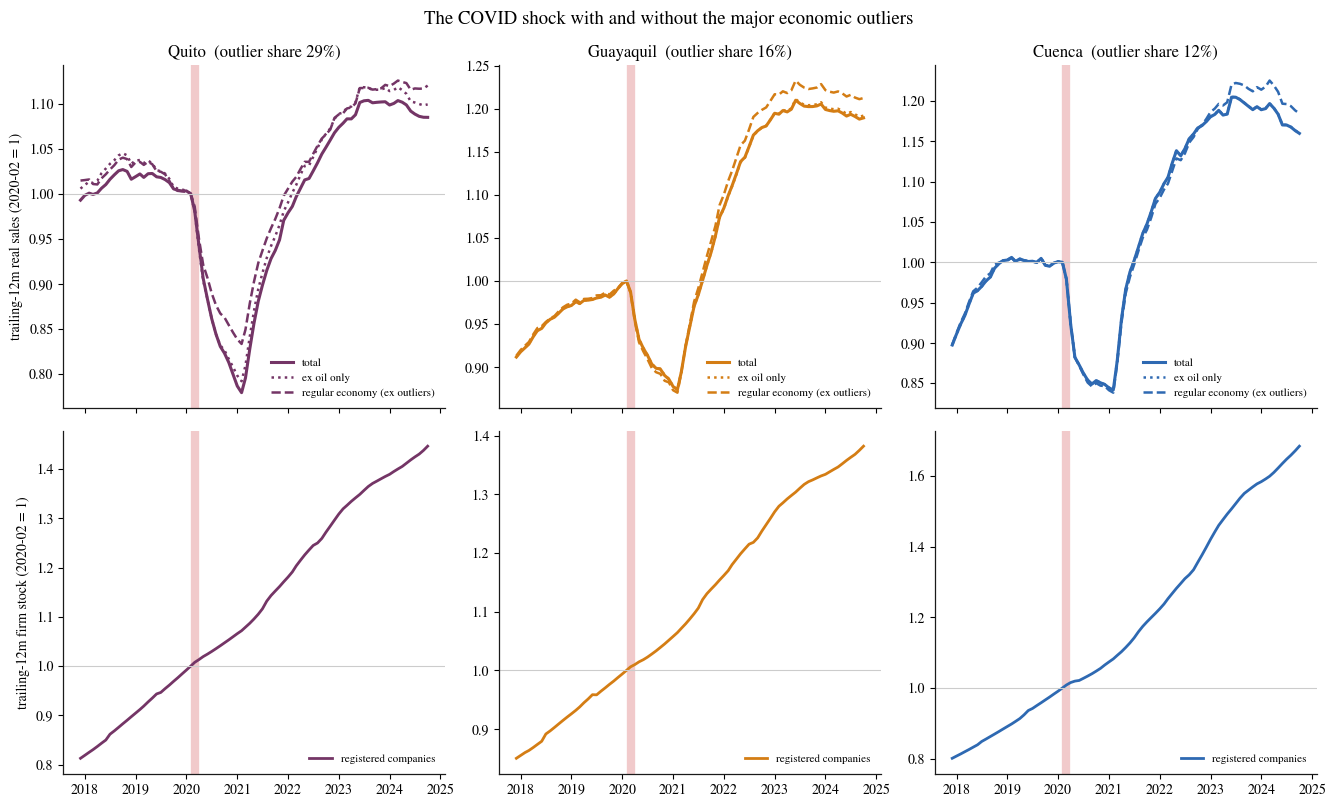

In [3]:
# ==============================================================================
# STEP C -- total / ex-oil / regular series; FIG 1: the three metros, two margins
# ==============================================================================
def monthly_units(d, val):
    'parish x month matrix of `val` on the full month grid, sample parishes'
    return (d.groupby(["unit", "ym"], observed=True)[val].sum()
            .unstack("unit").reindex(months).fillna(0.0)
            .reindex(columns=KEEP, fill_value=0.0))

S12_fin = monthly_units(fpr,                 "sales").rolling(12, min_periods=12).sum()
S12_oil = monthly_units(fpr[~fpr["oil"]],    "sales").rolling(12, min_periods=12).sum()
S12_reg = monthly_units(fpr[~fpr["outlier"]],"sales").rolling(12, min_periods=12).sum()
F12_cln = FIRMS_M[KEEP].rolling(12, min_periods=12).mean()     # registry firm stock (STEP A)
assert (S12_reg.loc[BENCH_P] > 0).all(), "a parish lost its whole benchmark to the flag"

VARIANTS = [("total",                       S12_fin, "-",  2.2),
            ("ex oil only",                 S12_oil, ":",  1.8),
            ("regular economy (ex outliers)", S12_reg, "--", 1.8)]

fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.2), sharex=True)
for c, (u, lab) in enumerate(METROS.items()):
    ax = axes[0, c]
    for tag, X12, ls_, lw_ in VARIANTS:
        s = (X12[u] / X12.loc[BENCH_P, u]).dropna()
        ax.plot(s.index.to_timestamp(), s.values, ls_, lw=lw_,
                color=METRO_C[lab], label=tag)
    ax.set_title(f"{lab}  (outlier share {OUT_SHARE[u]:.0%})", fontsize=12)
    ax = axes[1, c]
    for tag, X12, ls_ in [("registered companies", F12_cln, "-")]:
        s = (X12[u] / X12.loc[BENCH_P, u]).dropna()
        ax.plot(s.index.to_timestamp(), s.values, ls_, lw=2.0,
                color=METRO_C[lab], label=tag)
for ax in axes.ravel():
    ax.axhline(1.0, color="0.8", lw=0.8)
    ax.axvline(SHOCK_P.to_timestamp(), color=style.tint(style.RED, 0.6), lw=6, alpha=0.6, zorder=0)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
axes[0, 0].set_ylabel(f"trailing-12m real sales ({BENCH_P} = 1)", fontsize=10)
axes[1, 0].set_ylabel(f"trailing-12m firm stock ({BENCH_P} = 1)", fontsize=10)
fig.suptitle("The COVID shock with and without the major economic outliers", fontsize=13.5)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig1_metro_series.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "fig1_metro_series.pdf", bbox_inches="tight")
print("saved ->", OUT_DIR / "fig1_metro_series.png")
plt.show()

## STEP D — resistance and recovery, with and without the outliers

Same machinery as the resilience notebook: **resistance** = log-point depth of the
trailing-12m trough relative to the February-2020 benchmark (0 = never fell); **recovery**
= months from March 2020 until the series is back at the benchmark (NaN = censored, i.e.
not back by Oct 2024). We compute both for every sample parish on all three sales variants
— the parish cloud is what turns the metro comparison into a statement rather than an
anecdote — and cross-check the clean-panel totals against the saved
`resilience_metrics_parish.csv` to prove the constants really are the same.

cross-check vs resilience_metrics_parish.csv (clean-panel totals):
        res_cln  rec_cln  res_sales  rec_sales  match
170150  -0.2495     25.0    -0.2495       25.0   True
090150  -0.1347     17.0    -0.1347       17.0   True
010150  -0.1725     16.0    -0.1725       16.0   True 

--- the metros: trough depth (log pts) / months back to benchmark ---
  Quito      total -0.250 / 25m    ex-oil -0.233 / 23m    regular -0.182 / 22m
  Guayaquil  total -0.135 / 17m    ex-oil -0.134 / 17m    regular -0.139 / 17m
  Cuenca     total -0.172 / 16m    ex-oil -0.172 / 16m    regular -0.177 / 17m

resistance percentile among all parishes (higher = fell less), total -> regular:
  Quito 29% -> 39%   Guayaquil 51% -> 49%   Cuenca 41% -> 40%

saved -> results/resilience/regular_economy/fig2_resistance_recovery_bars.png


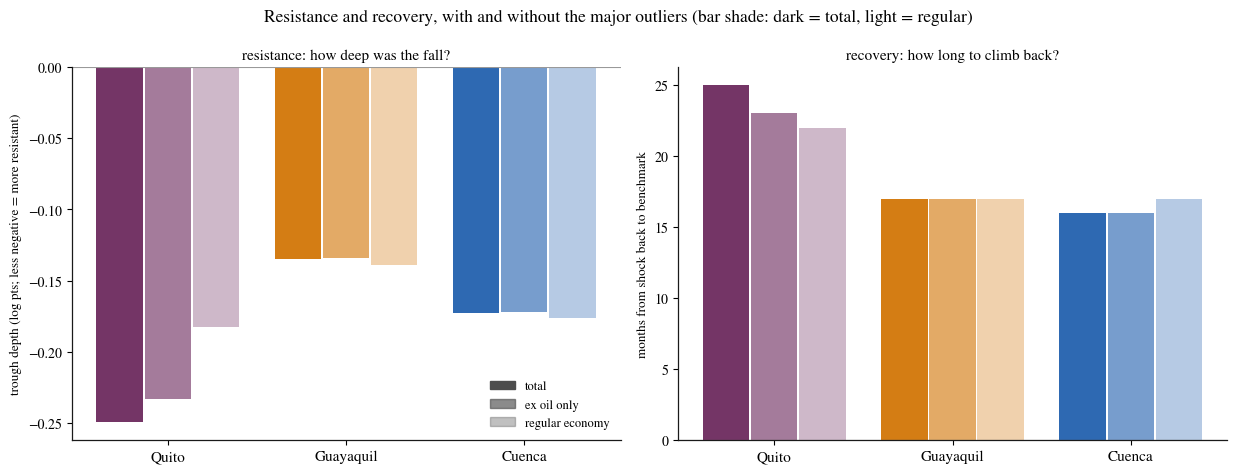

In [4]:
# ==============================================================================
# STEP D -- trough & recovery on every variant; FIG 2: the metros side by side
# ==============================================================================
def trough_and_recovery(X12):
    '''Per parish: trough depth (log pts, >= 0 if it never fell) of the
    trailing-12m series vs the pre-shock benchmark, and months from the shock
    back to the benchmark (0 = never fell, NaN = censored).'''
    bench = X12.loc[BENCH_P]
    win = X12.loc[SHOCK_P:TROUGH_P]
    trough, t_tr = win.min(), win.idxmin()
    depth = np.log(trough.where(trough > 0) / bench)
    rec = {}
    for u in X12.columns:
        if trough[u] >= bench[u]:
            rec[u] = 0.0
            continue
        back = X12.loc[t_tr[u]:, u]
        back = back[back >= bench[u]]
        rec[u] = float((back.index[0] - SHOCK_P).n) if len(back) else np.nan
    return depth, pd.Series(rec)

RES = pd.DataFrame({"name": [uname(u) for u in KEEP], "p0": P0}, index=KEEP)
for tag, X12 in [("cln", S12_cln[KEEP]), ("tot", S12_fin),
                 ("exoil", S12_oil), ("reg", S12_reg)]:
    RES[f"res_{tag}"], RES[f"rec_{tag}"] = trough_and_recovery(X12)
RES["res_firms"], RES["rec_firms"] = trough_and_recovery(F12_cln)   # registry firm stock
RES.to_csv(OUT_DIR / "metro_regular_resilience_metrics.csv")

# cross-check: the clean-panel totals must reproduce the existing metrics file
ref_path = paths.RESILIENCE / "resilience_metrics_parish.csv"
if ref_path.exists():
    ref = pd.read_csv(ref_path, dtype={"unit": str}).set_index("unit")
    chk = RES.loc[list(METROS), ["res_cln", "rec_cln"]].join(
        ref[["res_sales", "rec_sales"]])
    chk["match"] = (np.isclose(chk["res_cln"], chk["res_sales"], atol=1e-6)
                    & (chk["rec_cln"].fillna(-1) == chk["rec_sales"].fillna(-1)))
    print("cross-check vs resilience_metrics_parish.csv (clean-panel totals):")
    print(chk.round(4).to_string(), "\n")

print("--- the metros: trough depth (log pts) / months back to benchmark ---")
for u, lab in METROS.items():
    parts = []
    for tag, txt in [("tot", "total"), ("exoil", "ex-oil"), ("reg", "regular")]:
        rc = RES.loc[u, f"rec_{tag}"]
        parts.append(f"{txt} {RES.loc[u, f'res_{tag}']:+.3f} / "
                     f"{'censored' if pd.isna(rc) else f'{rc:.0f}m'}")
    print(f"  {lab:10s} " + "    ".join(parts))
pctl = lambda c, u: 100 * (RES[c] < RES.loc[u, c]).mean()
print("\nresistance percentile among all parishes (higher = fell less), total -> regular:")
print("  " + "   ".join(f"{lab} {pctl('res_tot', u):.0f}% -> {pctl('res_reg', u):.0f}%"
                        for u, lab in METROS.items()))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
x = np.arange(3)
for j, (col_root, ylab, ttl) in enumerate([
        ("res", "trough depth (log pts; less negative = more resistant)",
         "resistance: how deep was the fall?"),
        ("rec", "months from shock back to benchmark",
         "recovery: how long to climb back?")]):
    ax = axes[j]
    for k, (tag, txt, al) in enumerate([("tot", "total", 1.0),
                                        ("exoil", "ex oil", 0.65),
                                        ("reg", "regular economy", 0.35)]):
        vals = [RES.loc[u, f"{col_root}_{tag}"] for u in METROS]
        cols_ = [METRO_C[lab] for lab in METROS.values()]
        ax.bar(x + (k - 1) * 0.27, vals, width=0.26,
               color=cols_, alpha=al, edgecolor="none")
    ax.set_xticks(x); ax.set_xticklabels(METROS.values(), fontsize=11)
    ax.set_ylabel(ylab, fontsize=9.5)
    ax.set_title(ttl, fontsize=11)
    ax.axhline(0, color="0.6", lw=0.8)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color="0.3", alpha=a) for a in (1.0, 0.65, 0.35)]
axes[0].legend(handles, ["total", "ex oil only", "regular economy"],
               frameon=False, fontsize=9, loc="lower right")
fig.suptitle("Resistance and recovery, with and without the major outliers "
             "(bar shade: dark = total, light = regular)", fontsize=12.5)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig2_resistance_recovery_bars.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "fig2_resistance_recovery_bars.pdf", bbox_inches="tight")
print("\nsaved ->", OUT_DIR / "fig2_resistance_recovery_bars.png")
plt.show()

## STEP E — diversification: entropy over 239 activities at the 2019 baseline

Shannon entropy `H = −Σ s·ln(s)` over each parish's CIIU-4 group shares; `exp(H)` is the
**effective number of activities** (the count of equally-sized activities that would give
the same mix). A share is *the activity's part of the parish's 2019 sales*: if a parish
sold \$10 million and \$4 million of it came from retail trade, retail's share is 0.4.
Computed for the **full** economy and for the **regular** economy (the mix that actually
took the shock once outliers are removed).
The related/unrelated **variety split** decomposes group entropy exactly into
between-section (`UV`, insurance across unrelated industries) plus within-section
(`RV`, depth inside related industries); additivity is asserted to machine precision.

In [5]:
# ==============================================================================
# STEP E -- entropy and the variety split, full vs regular economy
# ==============================================================================
def H_of(sh):
    return -(sh * np.log(sh.where(sh > 0))).sum(axis=1)

def variety(comp, tag):
    'group entropy H = UV (between sections) + RV (within); plus exp(H)'
    sh = comp.div(comp.sum(axis=1), axis=0)
    H = H_of(sh)
    sec = sh.T.groupby(sh.columns.str[0]).sum().T
    UV = H_of(sec)
    RV = H - UV
    within = pd.Series(0.0, index=sh.index)
    for a in sec.columns:
        cols_a = [c for c in sh.columns if c[0] == a]
        cond = sh[cols_a].div(sec[a].where(sec[a] > 0), axis=0)
        within = within + (sec[a] * H_of(cond)).fillna(0.0)
    assert (H - UV - within).abs().max() < 1e-9, "entropy decomposition broken"
    return pd.DataFrame({f"H_{tag}": H, f"neff_{tag}": np.exp(H),
                         f"uv_{tag}": UV, f"rv_{tag}": RV})

W19_full = b19["sales19"].unstack(fill_value=0.0).reindex(KEEP).fillna(0.0)
W19_reg  = (b19.loc[~b19["outlier"], "sales19"].unstack(fill_value=0.0)
            .reindex(KEEP).fillna(0.0))

DIV = pd.concat([variety(W19_full, "sales"), variety(W19_reg, "sales_reg")], axis=1)
DIV.to_csv(OUT_DIR / "diversity_metrics.csv")

print("effective number of activities exp(H), sample medians:  "
      f"full {DIV['neff_sales'].median():.0f}, regular {DIV['neff_sales_reg'].median():.0f}\n")
print("--- the metros ---")
tbl = DIV.loc[list(METROS), ["neff_sales", "neff_sales_reg",
                             "uv_sales", "rv_sales", "uv_sales_reg", "rv_sales_reg"]]
tbl.index = [METROS[u] for u in tbl.index]
print(tbl.round(2).to_string())
print("\nreading: neff = how many equally-sized activities the mix is worth; "
      "uv = spread across unrelated sections (insurance), rv = depth within "
      "sections (related know-how). Removing the outliers barely changes the "
      "metros' diversity — the giants are a lot of dollars but few activities.")

effective number of activities exp(H), sample medians:  full 7, regular 8

--- the metros ---
           neff_sales  neff_sales_reg  uv_sales  rv_sales  uv_sales_reg  rv_sales_reg
Quito           58.44           60.69      2.10      1.97          2.09          2.01
Guayaquil       60.19           55.69      1.90      2.20          1.90          2.12
Cuenca          43.37           41.23      1.66      2.11          1.69          2.03

reading: neff = how many equally-sized activities the mix is worth; uv = spread across unrelated sections (insurance), rv = depth within sections (related know-how). Removing the outliers barely changes the metros' diversity — the giants are a lot of dollars but few activities.


## FIG 3 — breadth and the depth of the fall, in five groups

Three cities alone cannot answer whether a broad economy fell less, so the figure uses all
174 sample parishes. They are ordered by breadth (effective number of activities in 2019,
regular economy) and cut into **five groups of the same size**, 35 parishes each (one has 34). Every dot
is one parish; the height of the dot is the deepest fall of its sales, in percent, and inside a
group the dots also run from the narrowest parish on the left to the broadest on the right. Two
numbers summarise each group and are joined across groups:

- the **median fall**: half the parishes of the group fell more, half less;
- the **10th percentile**: the level that only one parish in ten of the group fell below.

If breadth protected against the shock on average, the black line would rise to the right. If
it goes with a shorter lower tail, the red line rises and the gap between the two closes.
The three cities are the coloured dots of the broadest group.

saved -> results/resilience/regular_economy/fig3_breadth_groups.png


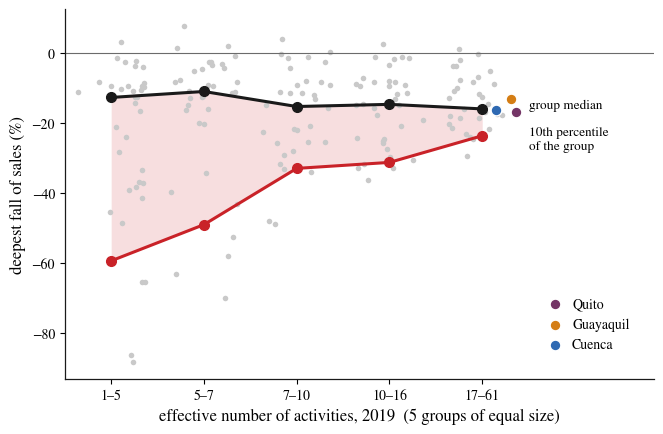


breadth vs trough depth across all sample parishes (Spearman):
  full economy   : rho = -0.034  (p = 0.6592, n = 174)
  regular economy: rho = +0.052  (p = 0.4935, n = 174)

worst regular-economy trough among the 13 parishes with >= 30 effective activities: -0.27 log pts
worst among the 161 less-diverse parishes:              -2.15 log pts


In [6]:
# ==============================================================================
# FIG 3 -- breadth and the depth of the fall: five groups of equal size
# ------------------------------------------------------------------------------
# Regular economy on both axes: breadth of the regular mix, trough of regular
# sales. N_GROUPS and BAD_CASE are the two choices; the checks in STEP K show
# the result does not depend on them.
# ==============================================================================
import scipy.stats as sps

N_GROUPS = 5            # groups of equal size, ordered by breadth
BAD_CASE = 0.10         # lower-tail quantile of a group: this share of its parishes fell further
SPREAD   = 0.36         # half-width of a group on the x axis
# the typical parish is drawn in ink, not blue: blue is Cuenca in this figure
TYPICAL_COLOR, BAD_COLOR = style.INK, style.RED


def binned_median(x, y, q=5):
    b = pd.qcut(x, q, duplicates="drop")
    g = pd.DataFrame({"x": x, "y": y}).groupby(b, observed=True)
    return g["x"].median(), g["y"].median()


def to_percent(log_points):
    """A change in log points as a percent change: -0.357 -> -30."""
    return np.expm1(log_points) * 100


breadth = DIV["neff_sales_reg"]
fall = RES["res_reg"]
GROUP = pd.qcut(breadth, N_GROUPS, labels=False)                 # 0 = narrowest ... 4 = broadest
GROUP_LABEL = [f"{breadth[GROUP == g].min():.0f}–{breadth[GROUP == g].max():.0f}"
               for g in range(N_GROUPS)]
typical = [to_percent(fall[GROUP == g].median()) for g in range(N_GROUPS)]
bad_case = [to_percent(fall[GROUP == g].quantile(BAD_CASE)) for g in range(N_GROUPS)]

# inside a group the dots also run from its narrowest parish (left edge) to its broadest
# (right edge), by ln(breadth): 0 at the group's minimum, 1 at its maximum
ln_b = np.log(breadth)
low, high = ln_b.groupby(GROUP).transform("min"), ln_b.groupby(GROUP).transform("max")
x_dot = GROUP + 2 * SPREAD * ((ln_b - low) / (high - low) - 0.5)

fig, ax = plt.subplots(figsize=(7.6, 4.8))
others = [u for u in KEEP if u not in METROS]
ax.scatter(x_dot[others], to_percent(fall[others]), s=16, color=style.CONTEXT, lw=0, zorder=2)
ax.fill_between(range(N_GROUPS), bad_case, typical, color=style.tint(style.RED, 0.85), lw=0, zorder=1)
ax.plot(range(N_GROUPS), typical, color=TYPICAL_COLOR, marker="o", ms=7, lw=2.2, zorder=4)
ax.plot(range(N_GROUPS), bad_case, color=BAD_COLOR, marker="o", ms=7, lw=2.2, zorder=4)
ax.text(N_GROUPS - 0.5, typical[-1] + 1, "group median", va="center", fontsize=9.5)
ax.text(N_GROUPS - 0.5, bad_case[-1] - 1, "10th percentile\nof the group", va="center", fontsize=9.5)
for u, lab in METROS.items():
    ax.scatter(x_dot[u], to_percent(fall[u]), s=60, color=METRO_C[lab], edgecolor="white", lw=1.0,
               zorder=6, label=lab)
ax.legend(loc="lower right", bbox_to_anchor=(0.98, 0.04), handletextpad=0.2)
ax.axhline(0, color=style.GREY, lw=0.8)
ax.set_xticks(range(N_GROUPS)); ax.set_xticklabels(GROUP_LABEL); ax.set_xlim(-0.5, N_GROUPS + 0.85)
ax.set_xlabel(f"effective number of activities, {T0_YEAR}  ({N_GROUPS} groups of equal size)")
ax.set_ylabel("deepest fall of sales (%)")
for ext in ("png", "pdf"):
    fig.savefig(OUT_DIR / f"fig3_breadth_groups.{ext}")
print("saved ->", OUT_DIR / "fig3_breadth_groups.png")
plt.show()

print("\nbreadth vs trough depth across all sample parishes (Spearman):")
for xc, yc, txt in [("neff_sales", "res_tot", "full economy   "),
                    ("neff_sales_reg", "res_reg", "regular economy")]:
    ok = DIV[xc].notna() & RES[yc].notna()
    r = sps.spearmanr(DIV.loc[ok, xc], RES.loc[ok, yc])
    print(f"  {txt}: rho = {r.statistic:+.3f}  (p = {r.pvalue:.4f}, n = {int(ok.sum())})")

# diversity as insurance against DISASTER rather than against the average hit:
NEFF_HI = 30
hi_d = DIV["neff_sales_reg"] >= NEFF_HI
print(f"\nworst regular-economy trough among the {int(hi_d.sum())} parishes with "
      f">= {NEFF_HI} effective activities: {RES.loc[hi_d, 'res_reg'].min():+.2f} log pts")
print(f"worst among the {int((~hi_d).sum())} less-diverse parishes:              "
      f"{RES.loc[~hi_d, 'res_reg'].min():+.2f} log pts")

## STEP G — how broad is Quito's economy, and how much of that is just size?

`exp(H)` from STEP E, read as the **effective number of activities**: the count of
equally-sized CIIU-4 activities that would produce the same mix. The left panel puts each
of the 174 sample parishes on that scale and marks the three metros — one parish at a
time, never a pooled "rest of the country", because pooling parishes inflates variety by
construction. The right panel plots the same measure against how many firms a parish has,
because breadth and size are very nearly the same variable: the trend line is how much
variety a parish of that size normally carries, and a metro's distance from it is the part
scale does *not* explain.

Breadth is measured on **sales shares** throughout, because sales are the only variable
the extract documents at the 4-character activity level. Size and STEP H's growth are the
number of companies on the *register*.

saved -> results/resilience/regular_economy/fig5_diversity_profile.png


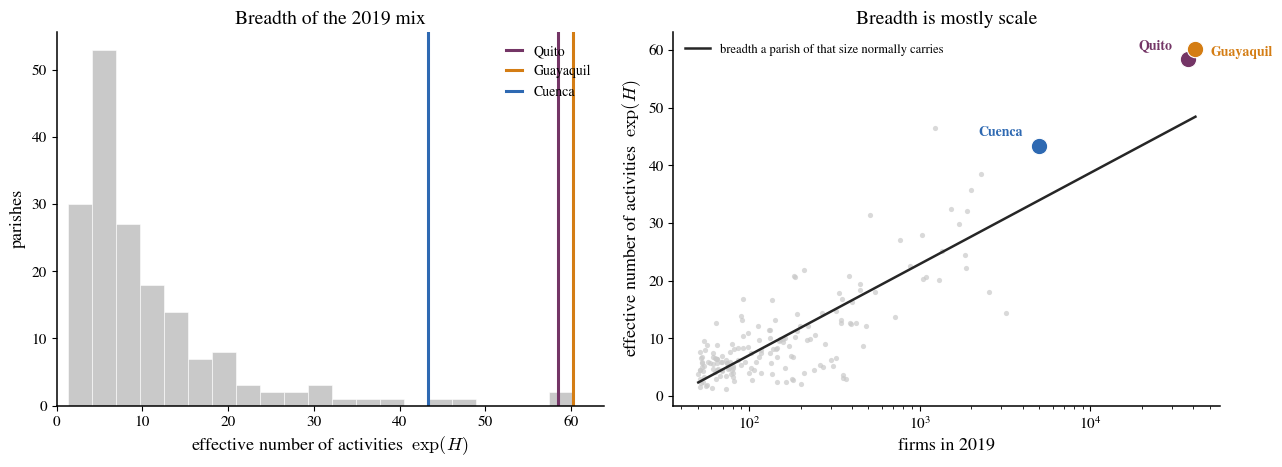


--- breadth of the 2019 mix, 174 sample parishes ---
median parish: 7 effective activities in the full economy, 8 in the regular economy

             full economy           regular economy
  Quito       58.4  (pct 98.9)    60.7  (pct 99.4)
  Guayaquil   60.2  (pct 99.4)    55.7  (pct 98.9)
  Cuenca      43.4  (pct 97.7)    41.2  (pct 97.1)

breadth vs size: Spearman rho = +0.648  -- most of the ranking IS size
breadth NOT explained by size (residual, + = broader than its size implies):
  Quito       +10.7   rank 4/174
  Guayaquil   +11.7   rank 3/174
  Cuenca       +9.5   rank 9/174


In [7]:
# ==============================================================================
# STEP G -- how broad is each economy, and how much of that is just size?
# ------------------------------------------------------------------------------
# WHY THIS STEP: the Quito story asks why its firm base kept expanding through a
# shock that hit its sales hardest. Before any of that, establish plainly HOW
# DIVERSIFIED Quito is next to everyone else -- against the sample parishes one
# at a time (pooling the rest of the country into one unit would hand it a
# bigger mix by construction, which is not a comparison).
#   panel (a): where the three metros sit in the national distribution of exp(H)
#   panel (b): the caveat drawn rather than buried -- exp(H) climbs steeply with
#              the number of firms a place has, so "Quito is diverse" is to a
#              first approximation "Quito is big". Distance from the trend line
#              is the breadth that scale does NOT buy.
# Diversity is the T0_YEAR baseline mix of SALES from STEP E (DIV); the size axis
# and STEP H's growth are the registry firm stock from STEP A (ANN_FIRMS).
# ==============================================================================
import scipy.stats as sps

MARGIN = "neff_sales"          # "neff_sales" | "neff_sales_reg"

# the serif look of the decomposition notebooks, applied with rc_context rather
# than globally: STEP F still runs after this cell and keeps the style it was
# published with.
REF_STYLE = {
    "font.family":      "STIXGeneral",
    "mathtext.fontset": "cm",
    "axes.titlesize":   14,
    "axes.labelsize":   13,
    "xtick.labelsize":  11,
    "ytick.labelsize":  11,
    "axes.linewidth":   1.1,
    "axes.edgecolor":   "black",
}

neff  = DIV[MARGIN]
size  = ANN_FIRMS.loc[KEEP, T0_YEAR]
lsize = np.log(size)

# breadth ~ log(size): the line drawn in panel (b) IS the line the residuals
# below are measured from, so "distance from the trend" is literally `resid`
FIT   = np.polyfit(lsize, neff, 1)
resid = neff - np.polyval(FIT, lsize)

DOT, METRO_DOT = 14, 140                    # cloud dot, highlighted metro dot
DXY = {"Quito": (-11, 7), "Guayaquil": (11, -5), "Cuenca": (-11, 7)}

with plt.rc_context(REF_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))

    # ---- (a) where the metros sit in the national distribution -------------------
    ax = axes[0]
    ax.hist(neff, bins="fd", color=GRAY_DOT, edgecolor="white", lw=0.4)
    for u, lab in METROS.items():
        ax.axvline(neff[u], color=METRO_C[lab], lw=2.2, label=lab)
    ax.set_xlabel(r"effective number of activities  $\exp(H)$")
    ax.set_ylabel("parishes")
    ax.set_xlim(0, neff.max() * 1.06)                 # keep Quito off the frame edge
    ax.set_title(f"Breadth of the {T0_YEAR} mix")
    ax.legend(frameon=False, fontsize=10, loc="upper right", handlelength=1.2)

    # ---- (b) ... and how much of that breadth is simply scale --------------------
    ax = axes[1]
    ax.scatter(size, neff, s=DOT, color=GRAY_DOT, alpha=0.70, lw=0)
    xg = np.linspace(lsize.min(), lsize.max(), 100)
    ax.plot(np.exp(xg), np.polyval(FIT, xg), color="0.15", lw=1.8,
            label="breadth a parish of that size normally carries")
    for u, lab in METROS.items():
        ax.scatter(size[u], neff[u], s=METRO_DOT, color=METRO_C[lab],
                   zorder=5, edgecolor="white", lw=0.8)
        dx, dy = DXY[lab]
        ax.annotate(lab, (size[u], neff[u]), textcoords="offset points",
                    xytext=(dx, dy), ha="left" if dx > 0 else "right",
                    fontsize=10, color=METRO_C[lab], fontweight="bold")
    ax.set_xscale("log")
    ax.set_xlabel(f"firms in {T0_YEAR}")
    ax.set_ylabel(r"effective number of activities  $\exp(H)$")
    ax.set_title("Breadth is mostly scale")
    ax.legend(frameon=False, fontsize=9, loc="upper left")

    for ax in axes:
        for s_ in ("top", "right"):
            ax.spines[s_].set_visible(False)

    fig.tight_layout()
    for ext in ("png", "pdf", "svg"):
        fig.savefig(OUT_DIR / f"fig5_diversity_profile.{ext}", dpi=200,
                    bbox_inches="tight")
    print("saved ->", OUT_DIR / "fig5_diversity_profile.png")
    plt.show()

# ---- the numbers behind the two panels ---------------------------------------
pctl_of = lambda s, u: 100 * (s < s[u]).mean()
print(f"\n--- breadth of the {T0_YEAR} mix, {len(KEEP)} sample parishes ---")
print(f"median parish: {neff.median():.0f} effective activities in the full "
      f"economy, {DIV['neff_sales_reg'].median():.0f} in the regular economy\n")
print("             full economy           regular economy")
for u, lab in METROS.items():
    print(f"  {lab:10s} {neff[u]:5.1f}  (pct {pctl_of(neff, u):4.1f})   "
          f"{DIV.loc[u, 'neff_sales_reg']:5.1f}  "
          f"(pct {pctl_of(DIV['neff_sales_reg'], u):4.1f})")

print(f"\nbreadth vs size: Spearman rho = {sps.spearmanr(neff, lsize).statistic:+.3f}"
      "  -- most of the ranking IS size")
print("breadth NOT explained by size (residual, + = broader than its size implies):")
for u, lab in METROS.items():
    print(f"  {lab:10s} {resid[u]:+6.1f}   rank {int((resid > resid[u]).sum()) + 1}"
          f"/{len(resid)}")

## STEP H — does breadth travel with keeping the firm base growing?

FIG 3 asked whether diversity softened the **sales** fall. It did not (ρ ≈ 0). This asks
whether it went with a **firm base that kept expanding**, which is the question the Quito
story actually rests on — and there the answer is yes (ρ = +0.29 in the full economy,
+0.28 in the regular mix, p < 0.001).

The result lives in the right panel, and it is about the floor rather than the middle.
Adding firms in 2019→20 was ordinary — 84 % of these parishes did it — so the quintile
difference that matters is not how *high* the top reaches but how *low* the bottom goes:
in the broadest quintile 34 of 35 parishes added firms and the one that did not lost about
1 %, against falls of 3 % to 23 % at the bottom of the other quintiles. That is the same
truncated-tail shape as the sales result in FIG 3, one margin over.

The caveat is printed under the figure rather than argued away: breadth and size are very
nearly the same variable (STEP G), and netting size out leaves nothing (ρ = +0.05, n.s.).
The claim this supports is *a broad base — which at this scale means a big one — keeps
growing when single activities collapse*, not *diversity causes growth*.

saved -> results/resilience/regular_economy/fig6_diversity_vs_firm_growth.png


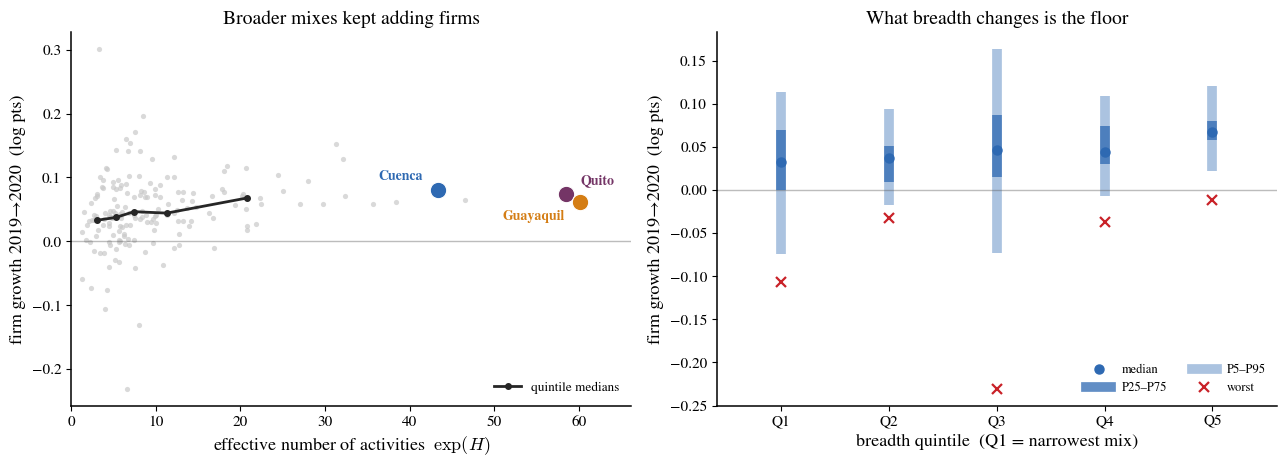


--- firm growth 2019->2020, 174 sample parishes ---
  147/174 = 84% added firms; median +0.046 log pts -- growing was the norm
  Quito      +0.0737 log (+7.7%)   rank 49/174
  Guayaquil  +0.0623 log (+6.4%)   rank 67/174
  Cuenca     +0.0803 log (+8.4%)   rank 39/174

breadth vs firm growth (Spearman):
  full economy : rho = +0.288  (p = 0.0001)
  regular mix  : rho = +0.275  (p = 0.0002)
  size-residual: rho = +0.046  (p = 0.5457)   <- net out size and the relationship is gone

by breadth quintile (neff_sales):
     n  neff_lo  neff_hi  median  share_positive  worst
q                                                      
Q1  35    1.276    4.457   0.033           0.743 -0.107
Q2  35    4.516    6.276   0.037           0.800 -0.032
Q3  34    6.300    8.802   0.046           0.824 -0.230
Q4  35    8.937   14.202   0.044           0.886 -0.037
Q5  35   14.320   60.185   0.068           0.971 -0.011


In [8]:
# ==============================================================================
# STEP H -- breadth vs keeping the firm base growing
# ------------------------------------------------------------------------------
# WHY THIS STEP: FIG 3 tested diversity against the depth of the SALES fall and
# found ~nothing. The Quito story needs the other margin -- whether a broader
# 2019 mix went with a firm stock that kept expanding across the shock window.
#   panel (a): FIG 3's twin, firm growth on the y axis, metros in the cloud
#   panel (b): the distribution of that growth inside each breadth quintile.
#              Read the BOTTOM of each band: growth was common everywhere, so
#              what breadth changes is the floor, not the ceiling.
# Growth is the registry firm stock (STEP A); breadth is the T0_YEAR mix (STEP E)
# and `resid` from STEP G is the same breadth with size netted out -- the printed
# Spearman on it is the honest bound on what this figure may claim.
# ==============================================================================
GROW_Y0, GROW_Y1 = SHOCK_Y0, SHOCK_Y1      # growth window (re-pointable)
N_QUINT = 5                                 # breadth bins
FIRM_C, FIRM_DOT = style.BLUE, style.tint(style.BLUE, 0.6)     # the "firms are blue" convention

G_FIRMS = np.log(ANN_FIRMS.loc[KEEP, GROW_Y1] / ANN_FIRMS.loc[KEEP, GROW_Y0])
qbin = pd.qcut(neff, N_QUINT, labels=[f"Q{i}" for i in range(1, N_QUINT + 1)])
DOT, METRO_DOT = 14, 140
DXY = {"Quito": (11, 7), "Guayaquil": (-11, -13), "Cuenca": (-11, 7)}

with plt.rc_context(REF_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))

    # ---- (a) the parish cloud, FIG 3's twin on the firm margin -------------------
    ax = axes[0]
    ax.scatter(neff, G_FIRMS, s=DOT, color=GRAY_DOT, alpha=0.70, lw=0)
    bx, by = binned_median(neff, G_FIRMS, q=N_QUINT)
    ax.plot(bx, by, color="0.15", lw=2.0, marker="o", ms=4, label="quintile medians")
    ax.axhline(0, color="0.35", lw=1.0, alpha=0.40, zorder=1)
    for u, lab in METROS.items():
        ax.scatter(neff[u], G_FIRMS[u], s=METRO_DOT, color=METRO_C[lab],
                   zorder=5, edgecolor="white", lw=0.8)
        dx, dy = DXY[lab]
        ax.annotate(lab, (neff[u], G_FIRMS[u]), textcoords="offset points",
                    xytext=(dx, dy), ha="left" if dx > 0 else "right",
                    fontsize=10, color=METRO_C[lab], fontweight="bold")
    ax.set_xlabel(r"effective number of activities  $\exp(H)$")
    ax.set_ylabel(f"firm growth {GROW_Y0}→{GROW_Y1}  (log pts)")
    ax.set_xlim(0, neff.max() * 1.10)                 # room for the Quito label
    ax.set_title("Broader mixes kept adding firms")
    ax.legend(frameon=False, fontsize=9.5, loc="lower right")

    # ---- (b) the same growth, quintile by quintile: the floor is the story --------
    ax = axes[1]
    for i, (_, g) in enumerate(G_FIRMS.groupby(qbin, observed=True)):
        p5, p25, p50, p75, p95 = np.percentile(g, [5, 25, 50, 75, 95])
        ax.vlines(i, p5, p95, color=FIRM_DOT, lw=7, zorder=2)
        ax.vlines(i, p25, p75, color=FIRM_C, lw=7, alpha=0.75, zorder=3)
        ax.plot(i, p50, "o", ms=6.5, color=FIRM_C, zorder=4)
        ax.plot(i, g.min(), "x", ms=7, color=CUSTOM_RED, mew=1.6, zorder=5)
    ax.axhline(0, color="0.35", lw=1.0, alpha=0.40)
    ax.set_xticks(range(N_QUINT))
    ax.set_xticklabels([f"Q{i}" for i in range(1, N_QUINT + 1)])
    ax.set_xlim(-0.6, N_QUINT - 0.4)
    ax.set_xlabel("breadth quintile  (Q1 = narrowest mix)")
    ax.set_ylabel(f"firm growth {GROW_Y0}→{GROW_Y1}  (log pts)")
    ax.set_title("What breadth changes is the floor")
    handles = [plt.Line2D([], [], color=FIRM_C, marker="o", ls="", ms=6.5),
               plt.Line2D([], [], color=FIRM_C, lw=7, alpha=0.75),
               plt.Line2D([], [], color=FIRM_DOT, lw=7),
               plt.Line2D([], [], color=CUSTOM_RED, marker="x", ls="", mew=1.6, ms=7)]
    ax.legend(handles, ["median", "P25–P75", "P5–P95", "worst"],
              frameon=False, fontsize=9, loc="lower right", ncol=2)

    for ax in axes:
        for s_ in ("top", "right"):
            ax.spines[s_].set_visible(False)

    fig.tight_layout()
    for ext in ("png", "pdf", "svg"):
        fig.savefig(OUT_DIR / f"fig6_diversity_vs_firm_growth.{ext}", dpi=200,
                    bbox_inches="tight")
    print("saved ->", OUT_DIR / "fig6_diversity_vs_firm_growth.png")
    plt.show()

# ---- the numbers ------------------------------------------------------------
print(f"\n--- firm growth {GROW_Y0}->{GROW_Y1}, {len(KEEP)} sample parishes ---")
print(f"  {int((G_FIRMS > 0).sum())}/{len(G_FIRMS)} = {(G_FIRMS > 0).mean():.0%} "
      f"added firms; median {G_FIRMS.median():+.3f} log pts -- growing was the norm")
for u, lab in METROS.items():
    print(f"  {lab:10s} {G_FIRMS[u]:+.4f} log ({np.expm1(G_FIRMS[u]):+.1%})   "
          f"rank {int((G_FIRMS > G_FIRMS[u]).sum()) + 1}/{len(G_FIRMS)}")

print("\nbreadth vs firm growth (Spearman):")
for col, txt in [("neff_sales", "full economy "), ("neff_sales_reg", "regular mix  ")]:
    r = sps.spearmanr(DIV[col], G_FIRMS)
    print(f"  {txt}: rho = {r.statistic:+.3f}  (p = {r.pvalue:.4f})")
r = sps.spearmanr(resid, G_FIRMS)
print(f"  size-residual: rho = {r.statistic:+.3f}  (p = {r.pvalue:.4f})"
      "   <- net out size and the relationship is gone")

print(f"\nby breadth quintile ({MARGIN}):")
tab = (pd.DataFrame({"g": G_FIRMS, "q": qbin, "neff": neff})
       .groupby("q", observed=True)
       .agg(n=("g", "size"), neff_lo=("neff", "min"), neff_hi=("neff", "max"),
            median=("g", "median"), share_positive=("g", lambda s: (s > 0).mean()),
            worst=("g", "min")))
print(tab.round(3).to_string())

## STEP I — the two margins: horizontal growth, vertical damage

Total real sales decompose **exactly** into the two margins an economy can move on:

$$\Delta\ln(\text{sales}) \;=\; \underbrace{\Delta\ln(\text{firms})}_{\text{horizontal / extensive}} \;+\; \underbrace{\Delta\ln(\text{sales per firm})}_{\text{vertical / intensive}}$$

so every parish is one point on a plane and every anti-diagonal is a constant total-sales
change (the identity is asserted in the cell). Colour is the 2019 breadth tercile, and the
figure's claim is in the two marginal densities: **breadth goes with more growth on the
horizontal margin and with no protection on the vertical one**. ρ = +0.29 (p = 0.0001)
against firm growth; ρ = −0.17 (p = 0.03) against sales per firm, that is, the broader
parishes saw a somewhat *larger* fall in sales per firm, not a smaller one.

That is the shape of Quito's story. It sits at the bottom of the plane — the deepest
vertical hit of the three metros, −0.30 log pts, 39th worst of 174 parishes — and still to
the *right* of zero, adding firms at +0.074. The broadest tercile as a whole does the same
thing: the worst intensive median of the three groups (−0.200, against −0.149 and −0.086)
and the group in which most parishes moved right (93 %, against 86 % and 74 %).
Diversification did not stop the economy from being pushed down; it went with spreading
sideways while that happened.

One caveat this figure inherits: sales per firm uses the *registry* firm count, in which a
company stays active until it suspends or cancels its registration. Part of the vertical
fall is therefore the denominator filling up with firms that may not be trading, not only
incumbent revenue collapsing.

saved -> results/resilience/regular_economy/fig7_two_margins.png


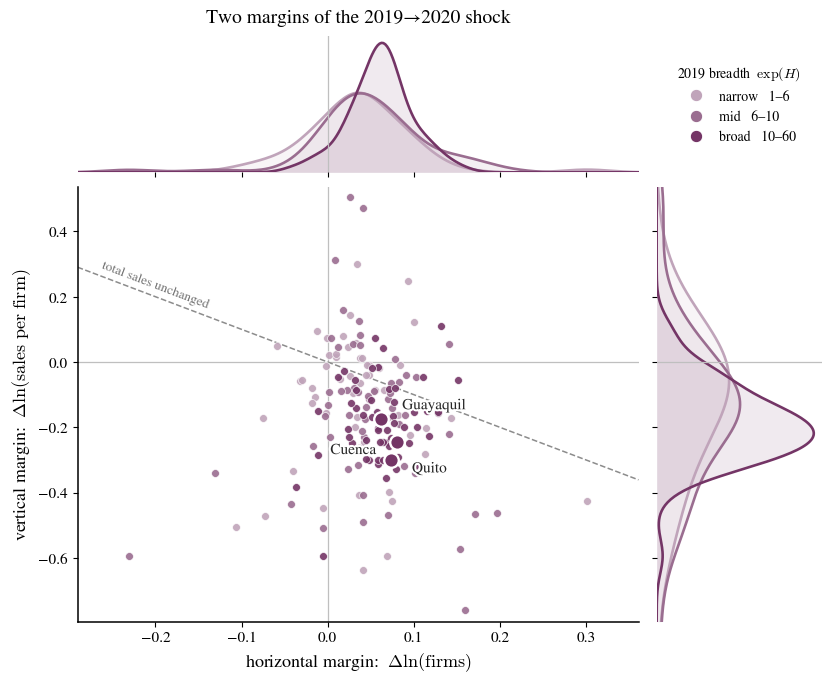


--- the two margins, 2019->2020 ---
  horizontal (firms):      median +0.046   84% of parishes positive
  vertical (sales/firm):   median -0.163   17% positive
  both together (sales):   median -0.100   25% positive

breadth moves ONE of the two margins (Spearman on exp(H)):
  horizontal (firms)     : rho = +0.288  (p = 0.0001)
  vertical (sales/firm)  : rho = -0.166  (p = 0.0281)
  total sales            : rho = -0.105  (p = 0.1685)

by breadth tercile:
             n  horizontal_median  share_moved_right  vertical_median  worst_vertical
neff_sales                                                                           
narrow      58              0.037              0.741           -0.086          -1.572
mid         58              0.041              0.862           -0.149          -0.961
broad       58              0.062              0.931           -0.200          -0.594

the vertical margin does not shift with breadth, but it does TIGHTEN:
  narrow  median -0.086   P5-P95 span 1

In [9]:
# ==============================================================================
# STEP I -- the two margins of the shock: horizontal (firms) vs vertical (size)
# ------------------------------------------------------------------------------
# WHY THIS STEP: STEP H put breadth against firm growth, which is only half the
# plane. Real sales split EXACTLY into the two margins a place can move on --
#     dln(sales) = dln(firms)  +  dln(sales per firm)
#                  ^ horizontal    ^ vertical
#                    (extensive)     (intensive)
# -- so one scatter holds both, and every anti-diagonal is a constant change in
# total sales. The marginal densities carry the argument: colour (2019 breadth
# tercile) separates the TOP marginal and not the RIGHT one. Breadth moves a
# parish sideways; it does nothing to how hard it is pushed down.
# Quito is the labelled case: the deepest vertical hit of the three metros, still
# moving right. Sales per firm uses the registry firm count (STEP G diagnostic),
# so read the vertical axis as sales per REGISTERED firm.
# ==============================================================================
from scipy.stats import gaussian_kde
from matplotlib import patheffects as pe

# breadth ramp: ONE hue, light -> dark, so colour reads as ordered. Steps are
# CVD-checked (worst adjacent dE 17.5 deutan/protan, 17.5 normal vision) and all
# three clear 3:1 contrast on white.
BREADTH_RAMP = style.ramp(style.PURPLE, 3)        # ordered groups: one colour, light to dark
TERCILE_LAB  = ["narrow", "mid", "broad"]
INK, RULE    = "0.15", "0.75"                    # text ink, reference rules
Y_CLIP       = (3, 99.5)                         # display percentiles, vertical axis

EXT = np.log(ANN_FIRMS.loc[KEEP, GROW_Y1] / ANN_FIRMS.loc[KEEP, GROW_Y0])
TOT = np.log(ANN_SALES.loc[KEEP, GROW_Y1] / ANN_SALES.loc[KEEP, GROW_Y0])
INT = TOT - EXT                                   # sales per firm, by the identity
assert np.allclose(TOT, EXT + INT), "the two margins must sum to total sales"

terc = pd.qcut(neff, 3, labels=TERCILE_LAB)
edges = [neff[terc == t].agg(["min", "max"]) for t in TERCILE_LAB]
DXY_I = {"Quito": (15, -9), "Guayaquil": (15, 7), "Cuenca": (-15, -9)}

with plt.rc_context(REF_STYLE):
    fig = plt.figure(figsize=(9.6, 7.6))
    gs  = fig.add_gridspec(2, 2, width_ratios=[3.4, 1], height_ratios=[1, 3.2],
                           wspace=0.05, hspace=0.05)
    ax  = fig.add_subplot(gs[1, 0])                       # the plane
    axt = fig.add_subplot(gs[0, 0], sharex=ax)            # horizontal marginal
    axr = fig.add_subplot(gs[1, 1], sharey=ax)            # vertical marginal
    axl = fig.add_subplot(gs[0, 1]); axl.set_axis_off()   # legend corner

    # ---- the plane -----------------------------------------------------------
    for lab, c in zip(TERCILE_LAB, BREADTH_RAMP):
        s = terc == lab
        ax.scatter(EXT[s], INT[s], s=32, color=c, alpha=0.9, lw=0.5,
                   edgecolor="white", zorder=3)
    ax.axvline(0, color=RULE, lw=0.9, zorder=1)
    ax.axhline(0, color=RULE, lw=0.9, zorder=1)

    pad = 0.06
    xlo, xhi = EXT.min() - pad, EXT.max() + pad
    ylo, yhi = np.percentile(INT, Y_CLIP) + np.array([-pad, pad])   # display clip;
    #          every printed number below still uses all 174 parishes
    ax.set_xlim(xlo, xhi); ax.set_ylim(ylo, yhi)
    xs = np.array([xlo, xhi])
    ax.plot(xs, -xs, ls="--", color="0.55", lw=1.1, zorder=2)   # total sales flat

    # label the diagonal along its own slope, in screen space
    p1, p2 = ax.transData.transform((xs[0], -xs[0])), ax.transData.transform((xs[1], -xs[1]))
    ang = np.degrees(np.arctan2(p2[1] - p1[1], p2[0] - p1[0]))
    xa = xlo + 0.04 * (xhi - xlo)
    ax.text(xa, -xa + 0.015, "total sales unchanged", rotation=ang,
            rotation_mode="anchor", color="0.45", fontsize=9.5, ha="left", va="bottom")

    for u, lab in METROS.items():
        ax.scatter(EXT[u], INT[u], s=110, color=BREADTH_RAMP[-1], zorder=5,
                   edgecolor="white", lw=1.7)
        dx, dy = DXY_I[lab]
        ax.annotate(lab, (EXT[u], INT[u]), textcoords="offset points", xytext=(dx, dy),
                    ha="left" if dx > 0 else "right", fontsize=11, color=INK, zorder=6,
                    path_effects=[pe.withStroke(linewidth=3.0, foreground="white")])
    ax.set_xlabel(r"horizontal margin:  $\Delta\ln(\mathrm{firms})$")
    ax.set_ylabel(r"vertical margin:  $\Delta\ln(\mathrm{sales\ per\ firm})$")
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)

    # ---- marginals: the top one separates by colour, the right one does not ---
    gx = np.linspace(xlo, xhi, 300)
    gy = np.linspace(ylo, yhi, 300)
    for lab, c in zip(TERCILE_LAB, BREADTH_RAMP):
        s = terc == lab
        dx_ = gaussian_kde(EXT[s])(gx)
        axt.plot(gx, dx_, color=c, lw=1.9)
        axt.fill_between(gx, dx_, color=c, alpha=0.10, lw=0)
        dy_ = gaussian_kde(INT[s])(gy)
        axr.plot(dy_, gy, color=c, lw=1.9)
        axr.fill_betweenx(gy, dy_, color=c, alpha=0.10, lw=0)
    axt.axvline(0, color=RULE, lw=0.9)
    axr.axhline(0, color=RULE, lw=0.9)
    axt.set_title(f"Two margins of the {GROW_Y0}→{GROW_Y1} shock", pad=10)
    for a in (axt, axr):
        a.set_ylim(bottom=0) if a is axt else a.set_xlim(left=0)
        for s_ in a.spines.values():
            s_.set_visible(False)
    axt.tick_params(left=False, labelleft=False, labelbottom=False)
    axr.tick_params(bottom=False, labelbottom=False, labelleft=False)

    # ---- legend in the empty corner ------------------------------------------
    handles = [plt.Line2D([], [], marker="o", ls="", ms=9, color=c,
                          mec="white", mew=0.8) for c in BREADTH_RAMP]
    labels = [f"{t}   {e['min']:.0f}–{e['max']:.0f}"
              for t, e in zip(TERCILE_LAB, edges)]
    leg = axl.legend(handles, labels, title=r"2019 breadth  $\exp(H)$",
                     loc="center", frameon=False, fontsize=10,
                     handletextpad=0.6, labelspacing=0.5)
    leg.get_title().set_fontsize(10)

    for ext_ in ("png", "pdf", "svg"):
        fig.savefig(OUT_DIR / f"fig7_two_margins.{ext_}", dpi=200, bbox_inches="tight")
    print("saved ->", OUT_DIR / "fig7_two_margins.png")
    plt.show()

# ---- the numbers -------------------------------------------------------------
print(f"\n--- the two margins, {GROW_Y0}->{GROW_Y1} ---")
print(f"  horizontal (firms):      median {EXT.median():+.3f}   "
      f"{(EXT > 0).mean():.0%} of parishes positive")
print(f"  vertical (sales/firm):   median {INT.median():+.3f}   "
      f"{(INT > 0).mean():.0%} positive")
print(f"  both together (sales):   median {TOT.median():+.3f}   "
      f"{(TOT > 0).mean():.0%} positive")

print("\nbreadth moves ONE of the two margins (Spearman on exp(H)):")
for v, nm in [(EXT, "horizontal (firms)     "), (INT, "vertical (sales/firm)  "),
              (TOT, "total sales            ")]:
    r = sps.spearmanr(neff, v)
    print(f"  {nm}: rho = {r.statistic:+.3f}  (p = {r.pvalue:.4f})")

print("\nby breadth tercile:")
print(pd.DataFrame({"n": terc.value_counts()[TERCILE_LAB],
                    "horizontal_median": EXT.groupby(terc, observed=True).median(),
                    "share_moved_right": EXT.groupby(terc, observed=True).apply(lambda s: (s > 0).mean()),
                    "vertical_median": INT.groupby(terc, observed=True).median(),
                    "worst_vertical": INT.groupby(terc, observed=True).min()}
                   ).round(3).to_string())

print("\nthe vertical margin does not shift with breadth, but it does TIGHTEN:")
for t in TERCILE_LAB:
    v = INT[terc == t]
    print(f"  {t:7s} median {v.median():+.3f}   P5-P95 span {np.ptp(np.percentile(v, [5, 95])):.3f}"
          f"   worst {v.min():+.3f}")
n_out = int((INT < ylo).sum())
print(f"  ({n_out} parish{'es' if n_out != 1 else ''} fall below the figure's display clip)")

print("\nthe metros on the plane:")
for u, lab in METROS.items():
    print(f"  {lab:10s} horizontal {EXT[u]:+.3f}   vertical {INT[u]:+.3f}   "
          f"total {TOT[u]:+.3f}   | vertical rank {int((INT < INT[u]).sum()) + 1}"
          f"/{len(INT)} from the bottom")

## STEP J — the same plane, as a path through time

FIG 7 is one snapshot: where every parish landed in the 2019→20 step. This is the same
plane with time running along it — each metro's trailing-12-month position relative to
**February 2020**, month by month from the end of 2017 to October 2024. Horizontal is still
the firm count, vertical is still sales per firm, and any anti-diagonal is still a constant
level of total real sales, so a path that runs *down the diagonal* is an economy holding
its sales while trading depth for count.

The shape is the argument. **Every metro moves right without pausing** — the horizontal
coordinate never falls in any month of the whole window, COVID included — while the
vertical coordinate falls off a cliff in 2020 and only partly climbs back. Quito's path
travels furthest down (−0.32 at its Feb-2021 trough) and keeps going right the entire time.
Cuenca's is the one to watch afterwards: its vertical coordinate is at its lowest in the
*last* month of the data, a slide that has nothing to do with the lockdown.

Each panel highlights one metro against the other two in grey, so the three paths are
never distinguished by colour alone — the panel title carries the identity.

saved -> results/resilience/regular_economy/fig8_margin_trajectories.png


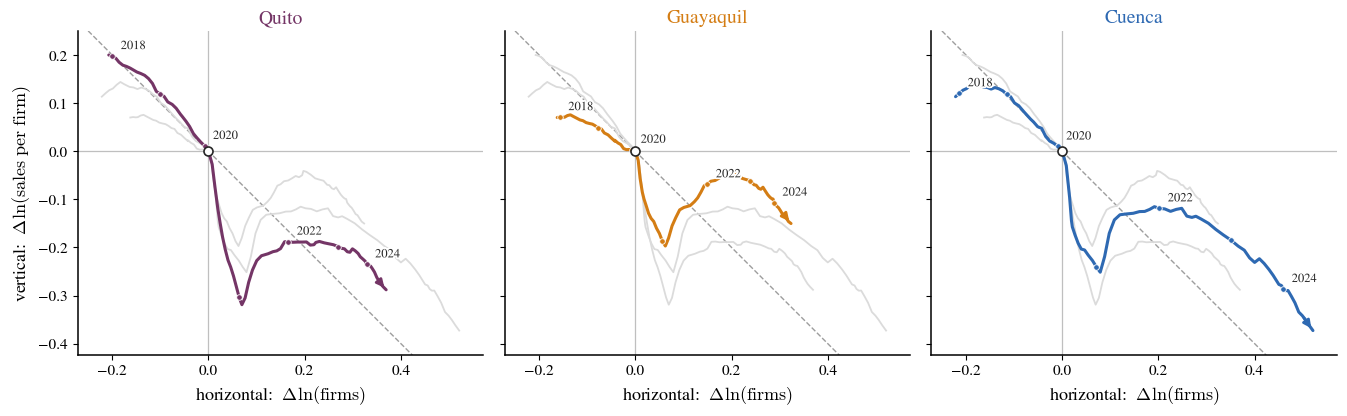


--- trailing-12m path vs 2020-02, 2017-12 to 2024-10 ---
  Quito      horizontal: -0.207 -> +0.369   biggest monthly fall +0.0031   |   vertical: trough -0.319 at 2021-02, ends -0.288
  Guayaquil  horizontal: -0.162 -> +0.324   biggest monthly fall -0.0003   |   vertical: trough -0.197 at 2021-02, ends -0.150
  Cuenca     horizontal: -0.222 -> +0.521   biggest monthly fall +0.0018   |   vertical: trough -0.373 at 2024-10, ends -0.373

the horizontal margin never gave anything back: the deepest one-month fall in ln(firms) across all three metros is -0.0003

annual steps on FIG 7's axes (dln firms, dln sales per firm):
                    17→18           18→19           19→20           20→21           21→22           22→23
Quito      +0.099, -0.076  +0.092, -0.105  +0.074, -0.300  +0.100, +0.093  +0.102, -0.006  +0.066, -0.034
Guayaquil  +0.079, -0.017  +0.071, -0.049  +0.062, -0.174  +0.093, +0.099  +0.087, +0.013  +0.056, -0.041
Cuenca     +0.098, +0.012  +0.106, -0.109  +0.080, -0.24

In [10]:
# ==============================================================================
# STEP J -- the metros' trajectories across the two-margin plane, 2017-2024
# ------------------------------------------------------------------------------
# WHY THIS STEP: FIG 7 freezes the plane at the COVID step. Here the same two
# margins are drawn as a PATH: each metro's trailing-12m position relative to
# BENCH_P (Feb 2020), one point per month, so time is the parameter.
#     x = ln( firms_12m / firms_12m(bench) )              horizontal / extensive
#     y = ln( (sales/firm)_12m / (sales/firm)_12m(bench) )  vertical / intensive
# x + y is still ln(sales / sales_bench), so the anti-diagonals still read as
# constant total real sales -- a path sliding DOWN a diagonal is an economy
# holding its sales while swapping depth for count.
# Small multiples rather than three overlaid paths: the metro palette's red and
# orange sit at the normal-vision discrimination floor, so identity goes in the
# panel title and colour only reinforces it. The two non-focus paths stay in grey
# for context.
# Firm counts are the REGISTRY stock (STEP G diagnostic), as everywhere else.
# ==============================================================================
TRAJ_BENCH = BENCH_P                       # origin of the plane (2020-02)
YEAR_LAB   = 2                             # label every Nth January
GHOST      = "0.86"

F12_CLN = FIRMS_M.rolling(12, min_periods=12).mean()      # trailing-12m firm stock


def margin_path(u, bench=TRAJ_BENCH):
    'trailing-12m (horizontal, vertical) coordinates of parish u vs `bench`.'
    f, s = F12_CLN[u].dropna(), S12_cln[u].dropna()
    ix = f.index.intersection(s.index)
    f, s = f[ix], s[ix]
    x = np.log(f / f[bench])
    y = np.log((s / f) / (s[bench] / f[bench]))
    return x, y


PATHS = {u: margin_path(u) for u in METROS}

with plt.rc_context(REF_STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(13.6, 5.0), sharex=True, sharey=True)
    for ax, (u, lab) in zip(axes, METROS.items()):
        c = METRO_C[lab]
        for v, other in METROS.items():                    # context, in grey
            if v != u:
                gx, gy = PATHS[v]
                ax.plot(gx.values, gy.values, color=GHOST, lw=1.3, zorder=1)
        x, y = PATHS[u]
        ax.plot(x.values, y.values, color=c, lw=2.2, zorder=3, solid_capstyle="round")

        jans = [p for p in x.index if p.month == 1]
        ax.scatter([x[p] for p in jans], [y[p] for p in jans], s=16, color=c,
                   zorder=4, edgecolor="white", lw=0.6)
        for p in jans[::YEAR_LAB]:
            ax.annotate(str(p.year), (x[p], y[p]), textcoords="offset points",
                        xytext=(6, 5), fontsize=9, color=INK, zorder=5,
                        path_effects=[pe.withStroke(linewidth=2.6, foreground="white")])
        ax.scatter([0], [0], s=42, facecolor="white", edgecolor=INK, lw=1.2, zorder=5)
        ax.annotate("", xy=(x.iloc[-1], y.iloc[-1]), xytext=(x.iloc[-4], y.iloc[-4]),
                    arrowprops=dict(arrowstyle="-|>", color=c, lw=2.0), zorder=4)
        ax.set_title(lab, color=c)
        ax.set_xlabel(r"horizontal:  $\Delta\ln(\mathrm{firms})$")
        for s_ in ("top", "right"):
            ax.spines[s_].set_visible(False)

    pad = 0.05
    xlo = min(x.min() for x, _ in PATHS.values()) - pad
    xhi = max(x.max() for x, _ in PATHS.values()) + pad
    ylo = min(y.min() for _, y in PATHS.values()) - pad
    yhi = max(y.max() for _, y in PATHS.values()) + pad
    for ax in axes:
        ax.axhline(0, color=RULE, lw=0.9, zorder=0)
        ax.axvline(0, color=RULE, lw=0.9, zorder=0)
        ax.set_xlim(xlo, xhi); ax.set_ylim(ylo, yhi)
        # equal aspect: a constant-total-sales line must LOOK like a 45 degree fall
        ax.set_aspect("equal", adjustable="box")
        d = np.array([min(xlo, -yhi), max(xhi, -ylo)])
        ax.plot(d, -d, ls="--", color="0.62", lw=1.0, zorder=0)
    axes[0].set_ylabel(r"vertical:  $\Delta\ln(\mathrm{sales\ per\ firm})$")
    fig.tight_layout()
    for ext_ in ("png", "pdf", "svg"):
        fig.savefig(OUT_DIR / f"fig8_margin_trajectories.{ext_}", dpi=200,
                    bbox_inches="tight")
    print("saved ->", OUT_DIR / "fig8_margin_trajectories.png")
    plt.show()

# ---- the numbers -------------------------------------------------------------
print(f"\n--- trailing-12m path vs {TRAJ_BENCH}, "
      f"{min(x.index[0] for x, _ in PATHS.values())} to "
      f"{max(x.index[-1] for x, _ in PATHS.values())} ---")
for u, lab in METROS.items():
    x, y = PATHS[u]
    print(f"  {lab:10s} horizontal: {x.iloc[0]:+.3f} -> {x.iloc[-1]:+.3f}   "
          f"biggest monthly fall {x.diff().min():+.4f}   |   vertical: trough "
          f"{y.min():+.3f} at {y.idxmin()}, ends {y.iloc[-1]:+.3f}")

print("\nthe horizontal margin never gave anything back: the deepest one-month fall in "
      f"ln(firms) across all three metros is {min(PATHS[u][0].diff().min() for u in METROS):+.4f}")

print(f"\nannual steps on FIG 7's axes (dln firms, dln sales per firm):")
steps = list(zip(FULL_YEARS[:-1], FULL_YEARS[1:]))
rows = {}
for u, lab in METROS.items():
    rows[lab] = {f"{a % 100:02d}→{b % 100:02d}":
                 (f"{np.log(ANN_FIRMS.loc[u, b] / ANN_FIRMS.loc[u, a]):+.3f}, "
                  f"{np.log(ANN_SALES.loc[u, b] / ANN_SALES.loc[u, a]) - np.log(ANN_FIRMS.loc[u, b] / ANN_FIRMS.loc[u, a]):+.3f}")
                 for a, b in steps}
print(pd.DataFrame(rows).T.to_string())
print("  every step is right of zero on the horizontal margin; only the rebound "
      "step is above zero on the vertical one.")

## STEP K — the same five groups, in two numbers each

FIG 3 shows every parish. This step reduces it to the two numbers that carry the claim, one
bar chart each, on the same axis so they can be compared at a glance:

- **left: the median fall of sales** in each group. If these bars are about the same height,
  breadth did not change how hard the ordinary parish was hit;
- **right: how many parishes of the group lost more than 30 % of their sales.** If these bars
  shrink to the right, breadth goes with fewer disasters.

Two checks follow, because five groups and a 30 % line are choices. **(1)** The spread of the
fall is compared across groups for two, three, four and five groups (Brown–Forsythe test: a
small p says the groups do not have the same spread). **(2)** No groups at all: a straight
line is fitted to the median and to the 10th percentile against breadth (quantile regression); the
claim needs the 10th-percentile line to rise and the median line not to.

The table also reports how many parishes of each group added firms in 2019→20. For the firm
margin the same test is printed, and it is *not* robust to the grouping: the claim is about
sales, not about the number of firms.

saved -> results/resilience/regular_economy/fig9_typical_vs_severe.png


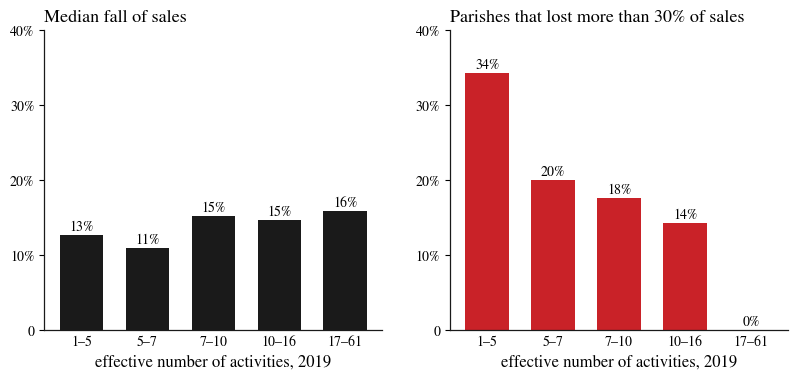


--- the five groups ---
breadth  parishes  typical_fall_pct  bad_case_pct  share_severe_pct  share_added_firms_pct
    1–5        35             -12.7         -59.4              34.3                   74.3
    5–7        35             -11.0         -49.0              20.0                   77.1
   7–10        34             -15.3         -32.9              17.6                   85.3
  10–16        35             -14.6         -31.2              14.3                   88.6
  17–61        35             -15.9         -23.6               0.0                   97.1

spread (standard deviation) of each group, narrowest to broadest; p = Brown-Forsythe test that the spreads are equal
  fall of sales halves    0.387 0.114   p = 0.0006
  fall of sales terciles  0.424 0.238 0.104   p = 0.0126
  fall of sales quartiles 0.473 0.265 0.133 0.092   p = 0.0015
  fall of sales quintiles 0.503 0.304 0.174 0.132 0.088   p = 0.0036
  firm growth   halves    0.067 0.041   p = 0.0215
  firm growth   terc

In [11]:
# ==============================================================================
# STEP K -- median fall vs severe falls, by breadth group; and two checks
# ==============================================================================
import statsmodels.api as sm

SEVERE = 0.30                       # a severe fall: more than this share of sales lost
severe_log = np.log(1 - SEVERE)     # the same line in log points

BY_GROUP = pd.DataFrame({
    "breadth": GROUP_LABEL,
    "parishes": [int((GROUP == g).sum()) for g in range(N_GROUPS)],
    "typical_fall_pct": typical,
    "bad_case_pct": bad_case,
    "share_severe_pct": [(fall[GROUP == g] < severe_log).mean() * 100 for g in range(N_GROUPS)],
    "share_added_firms_pct": [(G_FIRMS[GROUP == g] > 0).mean() * 100 for g in range(N_GROUPS)],
})
BY_GROUP.to_csv(OUT_DIR / "breadth_groups.csv", index=False)

TOP = 40                             # both panels share the 0-40 % axis
fig, (left, right) = plt.subplots(1, 2, figsize=(9.6, 3.9))
left.bar(range(N_GROUPS), -BY_GROUP["typical_fall_pct"], color=TYPICAL_COLOR, width=0.66)      # same colours as FIG 3
right.bar(range(N_GROUPS), BY_GROUP["share_severe_pct"], color=BAD_COLOR, width=0.66)
for ax, values in [(left, -BY_GROUP["typical_fall_pct"]), (right, BY_GROUP["share_severe_pct"])]:
    for g, v in enumerate(values):
        ax.text(g, v + 0.6, f"{v:.0f}%", ha="center", fontsize=10)
    ax.set_xticks(range(N_GROUPS)); ax.set_xticklabels(GROUP_LABEL)
    ax.set_xlabel(f"effective number of activities, {T0_YEAR}")
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, TOP); ax.set_yticks([0, 10, 20, 30, 40]); ax.set_yticklabels(["0", "10%", "20%", "30%", "40%"])
left.set_title("Median fall of sales", loc="left")
right.set_title(f"Parishes that lost more than {SEVERE:.0%} of sales", loc="left")
for ext in ("png", "pdf"):
    fig.savefig(OUT_DIR / f"fig9_typical_vs_severe.{ext}")
print("saved ->", OUT_DIR / "fig9_typical_vs_severe.png")
plt.show()

print("\n--- the five groups ---")
print(BY_GROUP.round(1).to_string(index=False))

# ---- check 1: does the spread shrink however the parishes are grouped? ----------
print("\nspread (standard deviation) of each group, narrowest to broadest; "
      "p = Brown-Forsythe test that the spreads are equal")
for label, outcome in [("fall of sales", fall), ("firm growth  ", G_FIRMS)]:
    for k, name in [(2, "halves"), (3, "terciles"), (4, "quartiles"), (5, "quintiles")]:
        g = pd.qcut(breadth, k, labels=False)
        groups = [outcome[g == i].values for i in range(k)]
        p = sps.levene(*groups, center="median").pvalue
        print(f"  {label} {name:9s} " + " ".join(f"{v.std(ddof=1):.3f}" for v in groups) + f"   p = {p:.4f}")

# ---- check 2: no groups at all -------------------------------------------------
X = sm.add_constant(np.log(breadth).rename("ln_breadth"))
print("\nfitted lines against ln(breadth), no groups (quantile regression):")
for q, name in [(BAD_CASE, "10th percentile"), (0.50, "median         ")]:
    m = sm.QuantReg(fall, X).fit(q=q)
    at = [float(m.predict(np.array([[1.0, np.log(v)]]))[0]) for v in (3, 10, 30)]
    print(f"  {name}: slope {m.params['ln_breadth']:+.3f} (p = {m.pvalues['ln_breadth']:.4f});  "
          f"fall at 3 / 10 / 30 activities: " + " / ".join(f"{to_percent(a):+.0f}%" for a in at))

## STEP K (cont.) — the same claim as fitted distributions

FIG 3 shows the parishes and the bars of STEP K show two numbers per group. This figure shows
the whole shape: one fitted curve per breadth group, for the deepest fall of sales (left) and
for the growth of the number of firms in 2019→20 (right). The vertical line of each colour is
the median of that group.

What to look for on the left: the three medians are almost in the same place, and the curve
of the narrowest group has a long tail towards large falls that the broadest group does not
have. On the right the curves move to the right and tighten with breadth, but STEP K showed
that this tightening is not robust to the grouping, so the claim stays with sales.

**Three groups, not five.** A curve needs more parishes than a median does (58 per group
instead of 35), and five overlapping curves cannot be told apart. The check of STEP K covers
this grouping (row "terciles"). The curves are continuous fits, the rule of the three-period
figure in `decomp_season_data_analysis.ipynb`: a skewed Student-t when it describes the data
clearly better than a Gaussian, otherwise the Gaussian.

saved -> results/resilience/regular_economy/fig11_breadth_distributions.png


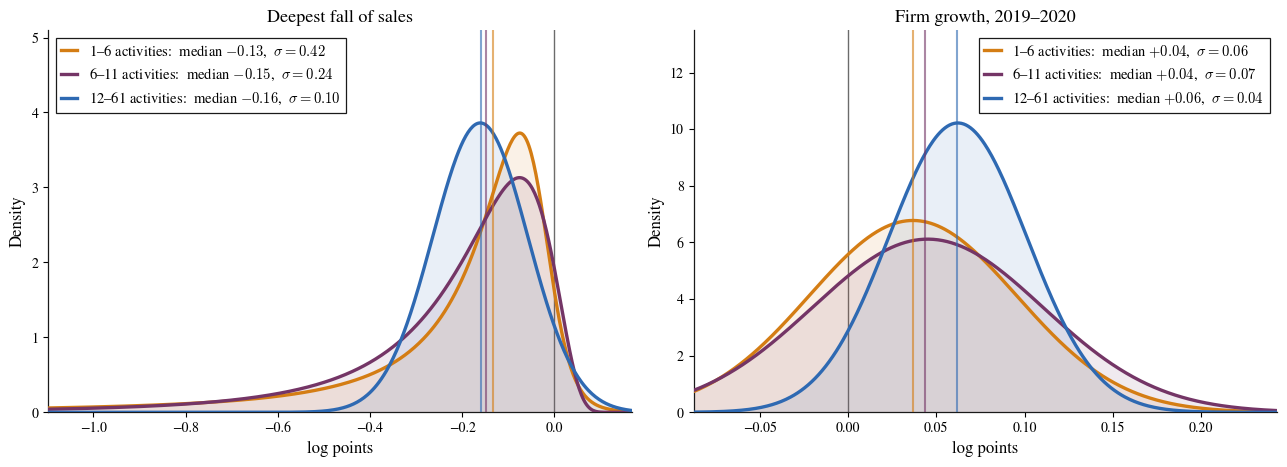


--- the curves (log points) ---
               outcome activities  parishes  median    sd      fit  outside_axis
 Deepest fall of sales        1–6        58  -0.132 0.424   skew-t             2
 Deepest fall of sales       6–11        58  -0.149 0.238   skew-t             1
 Deepest fall of sales      12–61        58  -0.159 0.104 Gaussian             0
Firm growth, 2019–2020        1–6        58   0.037 0.059 Gaussian             2
Firm growth, 2019–2020       6–11        58   0.043 0.066 Gaussian             2
Firm growth, 2019–2020      12–61        58   0.062 0.039 Gaussian             0


In [12]:
# ==============================================================================
# STEP K (cont.) -- the same claim as fitted distributions, one curve per group
# ------------------------------------------------------------------------------
# The idiom of the three-period figure: a continuous fit per group, a light
# fill under it, a faded vertical line at the group's median, and the two
# numbers that matter (median, standard deviation) in a boxed legend.
# ==============================================================================
import warnings

N_CURVES   = 3                      # groups of equal size, ordered by breadth
AIC_MARGIN = 10.0                   # the skew-t must beat the Gaussian by this much (AIC)
X_CLIP     = (3, 99.5)              # percentiles of the outcome that bound the x axis
HEADROOM   = 1.32                   # room above the curves for the legend
# overlapping curves need colours that differ: three colours for three groups,
# and one colour from light to dark for any other number of groups
CURVE_COLORS = style.GROUPS_3 if N_CURVES == 3 else style.ramp(style.PURPLE, N_CURVES)


def fitted_density(x, grid):
    """The fitted curve of x on grid, and the name of the fit: a skewed
    Student-t if it beats the Gaussian by AIC_MARGIN, otherwise the Gaussian."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        skew_t = sps.jf_skew_t(*sps.jf_skew_t.fit(x))
    gauss = sps.norm(x.mean(), x.std(ddof=0))
    aic_gauss = 2 * 2 - 2 * gauss.logpdf(x).sum()       # 2 parameters
    aic_skew_t = 2 * 4 - 2 * skew_t.logpdf(x).sum()     # 4 parameters
    if aic_gauss - aic_skew_t > AIC_MARGIN:
        return skew_t.pdf(grid), "skew-t"
    return gauss.pdf(grid), "Gaussian"


CURVE_GROUP = pd.qcut(breadth, N_CURVES, labels=False)            # 0 = narrowest
CURVE_LABEL = [f"{breadth[CURVE_GROUP == g].min():.0f}–{breadth[CURVE_GROUP == g].max():.0f}"
               for g in range(N_CURVES)]

#           outcome   panel title                             legend corner
PANELS = [(fall,    "Deepest fall of sales",                 "upper left"),
          (G_FIRMS, f"Firm growth, {GROW_Y0}–{GROW_Y1}",     "upper right")]

rows = []
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))
for ax, (outcome, title, corner) in zip(axes, PANELS):
    low, high = np.percentile(outcome, X_CLIP)
    pad = 0.12 * (high - low)
    grid = np.linspace(low - pad, high + pad, 500)
    peak = 0.0
    for g in range(N_CURVES):
        x = outcome[CURVE_GROUP == g].values
        density, fit = fitted_density(x, grid)
        median, sd = np.median(x), x.std(ddof=1)
        label = (f"{CURVE_LABEL[g]} activities:  median ${median:+.2f}$,  $\\sigma = {sd:.2f}$")
        ax.plot(grid, density, color=CURVE_COLORS[g], lw=2.4, zorder=3, label=label)
        ax.fill_between(grid, density, color=CURVE_COLORS[g], alpha=0.10, lw=0, zorder=2)
        ax.axvline(median, color=CURVE_COLORS[g], lw=1.5, alpha=0.6, zorder=4)
        peak = max(peak, density.max())
        rows.append({"outcome": title, "activities": CURVE_LABEL[g], "parishes": len(x),
                     "median": median, "sd": sd, "fit": fit,
                     "outside_axis": int(((x < grid[0]) | (x > grid[-1])).sum())})
    ax.axvline(0, color=style.GREY, lw=1.0, zorder=1)
    ax.set_xlim(grid[0], grid[-1])
    ax.set_ylim(0, peak * HEADROOM)
    ax.set_title(title)
    ax.set_xlabel("log points")
    ax.set_ylabel("Density")
    legend = ax.legend(loc=corner, fontsize=10.5, frameon=True, fancybox=False, edgecolor=style.INK,
                       framealpha=1.0, handlelength=1.1)
    legend.get_frame().set_linewidth(0.9)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(OUT_DIR / f"fig11_breadth_distributions.{ext}")
print("saved ->", OUT_DIR / "fig11_breadth_distributions.png")
plt.show()

print("\n--- the curves (log points) ---")
print(pd.DataFrame(rows).round(3).to_string(index=False))


## STEP L — which sectors withstood the shock, and on which margin

The same two margins, one level down: each CIIU section's own horizontal and vertical change,
one row apiece on a shared axis.

**Vertically, sector matters enormously.** Hotels & food (−0.57), arts (−0.52) and
construction (−0.49) were gutted; water/waste (+0.02), agriculture (−0.09) and health (−0.10)
barely moved — a 0.58 log-point range. **Horizontally, sector hardly matters at all**: 17 of
19 sections still added firms, across a range of only 0.19 log points.

And the two margins do not line up. The relationship is weak, insignificant and if anything
*negative* (Pearson −0.27, n = 19) — the sectors hit hardest on revenue were adding firms
slightly faster, not slower. Hotels & food took the worst vertical hit in the economy *and*
grew its firm count faster than average; construction was third-worst vertically and
second-highest horizontally.

So no sector defended the vertical margin, and being hit hardest there did not stop a sector
from expanding horizontally — the same asymmetry the parish panels show, one level down.

saved -> results/resilience/regular_economy/fig10_sector_margins.png


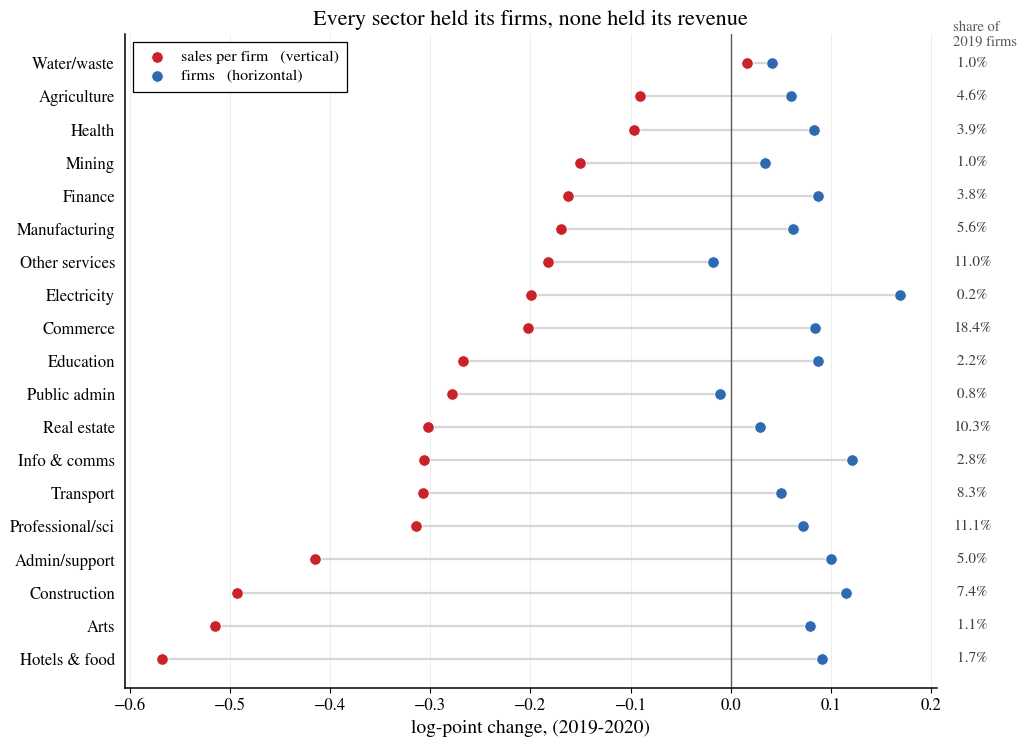


--- the 19 CIIU sections, 2019->2020 ---
                       name  share_%  horizontal  vertical
cod_ciuu4                                                 
I             Hotels & food      1.7       0.091    -0.568
R                      Arts      1.1       0.079    -0.515
F              Construction      7.4       0.115    -0.493
N             Admin/support      5.0       0.100    -0.415
M          Professional/sci     11.1       0.072    -0.314
H                 Transport      8.3       0.050    -0.308
J              Info & comms      2.8       0.121    -0.306
L               Real estate     10.3       0.029    -0.302
O              Public admin      0.8      -0.010    -0.278
P                 Education      2.2       0.087    -0.267
G                  Commerce     18.4       0.084    -0.203
D               Electricity      0.2       0.169    -0.199
S            Other services     11.0      -0.018    -0.182
C             Manufacturing      5.6       0.062    -0.170
K             

In [13]:
# ==============================================================================
# STEP L -- the sections: both margins, one row each
# ------------------------------------------------------------------------------
# WHY THIS STEP: the other half of the answer. If breadth protects the horizontal
# margin, is that because some SECTORS are built to hold it? The dumbbell puts
# each CIIU section's two margins on one row: blue = its firm count, red = its
# sales per firm. The panel's shape is the finding -- blue in a tight file just
# right of zero, red fanned out to the left.
# A dumbbell rather than the two-margin plane: the sections' horizontal range is
# 0.19 log points against 0.58 vertical, so on a plane they stack into an
# unreadable column. One row each puts the names on the axis.
# Sections are the clean panel's cod_ciuu4 letter, so their firm counts are the
# same registry stock used everywhere else.
# ==============================================================================
from matplotlib.transforms import blended_transform_factory

MIN_SEC_FIRMS = 50                  # sections smaller than this are noise
DROP_SEC = {"V"}                    # unlabelled residual class
FIRM_MC, SALES_MC = style.BLUE, style.RED    # horizontal / vertical margin
SEC_NAME = {
    "A": "Agriculture", "B": "Mining", "C": "Manufacturing", "D": "Electricity",
    "E": "Water/waste", "F": "Construction", "G": "Commerce", "H": "Transport",
    "I": "Hotels & food", "J": "Info & comms", "K": "Finance", "L": "Real estate",
    "M": "Professional/sci", "N": "Admin/support", "O": "Public admin",
    "P": "Education", "Q": "Health", "R": "Arts", "S": "Other services",
    "T": "Households", "U": "Extraterritorial"}

sec = pd.read_parquet(paths.FIRM_REVENUE_PARQUET,
                      columns=["anio", "mes", "cod_ciuu4", "total_sales", "total_firms"])
sec["year"] = sec["anio"].astype(int)
sec = sec[sec["year"].isin([SHOCK_Y0, SHOCK_Y1])]
sec["real_sales"] = sec["total_sales"] * sec["year"].map(IPC_F)
sg = (sec.groupby(["cod_ciuu4", "year"])
      .agg(s=("real_sales", "sum"), fmonths=("total_firms", "sum")))
sg["f"] = sg["fmonths"] / 12.0
SEC = pd.DataFrame({"f0": sg["f"].unstack("year")[SHOCK_Y0],
                    "f1": sg["f"].unstack("year")[SHOCK_Y1],
                    "s0": sg["s"].unstack("year")[SHOCK_Y0],
                    "s1": sg["s"].unstack("year")[SHOCK_Y1]}).dropna()
SEC = SEC[(SEC["f0"] >= MIN_SEC_FIRMS) & ~SEC.index.isin(DROP_SEC)]
SEC["horizontal"] = np.log(SEC["f1"] / SEC["f0"])
SEC["vertical"] = np.log((SEC["s1"] / SEC["f1"]) / (SEC["s0"] / SEC["f0"]))
SEC["share"] = SEC["f0"] / SEC["f0"].sum()
SEC["name"] = [SEC_NAME.get(i, i) for i in SEC.index]

# bigger type for this tall figure
OVERLAY_STYLE = {
    "font.family":      "STIXGeneral",
    "mathtext.fontset": "cm",
    "axes.titlesize":   16,
    "axes.labelsize":   14,
    "xtick.labelsize":  12,
    "ytick.labelsize":  12,
    "axes.linewidth":   1.1,
    "axes.edgecolor":   "black",
}

with plt.rc_context(OVERLAY_STYLE):
    fig, ax = plt.subplots(figsize=(10.4, 7.6))
    ordered = SEC.sort_values("vertical")
    ypos = np.arange(len(ordered))
    ax.hlines(ypos, ordered["vertical"], ordered["horizontal"],
              color="0.84", lw=1.6, zorder=1)
    ax.scatter(ordered["vertical"], ypos, s=70, color=SALES_MC, zorder=3,
               edgecolor="white", lw=0.7, label="sales per firm   (vertical)")
    ax.scatter(ordered["horizontal"], ypos, s=70, color=FIRM_MC, zorder=3,
               edgecolor="white", lw=0.7, label="firms   (horizontal)")
    ax.axvline(0, color="0.35", lw=1.0, zorder=2)
    ax.set_yticks(ypos); ax.set_yticklabels(ordered["name"])
    ax.set_ylim(-0.9, len(ordered) - 0.1)
    ax.set_xlabel(f"log-point change, ({SHOCK_Y0}-{SHOCK_Y1})")
    ax.set_title("Every sector held its firms, none held its revenue")
    ax.grid(axis="x", color="0.93", lw=0.7); ax.set_axisbelow(True)
    ax.tick_params(left=False)
    lg = ax.legend(loc="upper left", fontsize=11.5, frameon=True, fancybox=False,
                   edgecolor="black", framealpha=1.0, handletextpad=0.5,
                   borderpad=0.5, labelspacing=0.35)
    lg.get_frame().set_linewidth(0.9)

    # each section's weight in the economy, as its own column
    tr = blended_transform_factory(ax.transAxes, ax.transData)
    ax.text(1.02, len(ordered) - 0.15, "share of\n2019 firms", transform=tr,
            va="center", ha="left", fontsize=10.5, color="0.35")
    for y, sh in enumerate(ordered["share"]):
        ax.text(1.02, y, f"{sh * 100:4.1f}%", transform=tr, va="center",
                ha="left", fontsize=11, color="0.25")

    fig.tight_layout()
    for ext_ in ("png", "pdf", "svg"):
        fig.savefig(OUT_DIR / f"fig10_sector_margins.{ext_}", dpi=200,
                    bbox_inches="tight")
    print("saved ->", OUT_DIR / "fig10_sector_margins.png")
    plt.show()

print(f"\n--- the {len(SEC)} CIIU sections, {SHOCK_Y0}->{SHOCK_Y1} ---")
print(SEC.sort_values("vertical")[["name", "share", "horizontal", "vertical"]]
      .assign(share=lambda d: (d["share"] * 100).round(1))
      .rename(columns={"share": "share_%"}).round(3).to_string())
print(f"\n  horizontal range {np.ptp(SEC['horizontal']):.3f} log pts, "
      f"{int((SEC['horizontal'] > 0).sum())}/{len(SEC)} sections still adding firms")
print(f"  vertical range   {np.ptp(SEC['vertical']):.3f} log pts, "
      f"{int((SEC['vertical'] > 0).sum())}/{len(SEC)} sections holding sales per firm")
r_sec = sps.spearmanr(SEC["horizontal"], SEC["vertical"])
print(f"  correlation between the two margins across sections: "
      f"Pearson {SEC['horizontal'].corr(SEC['vertical']):+.3f}, "
      f"Spearman {r_sec.statistic:+.3f} (p = {r_sec.pvalue:.3f}, n = {len(SEC)})")
print("  -- weak, not significant, and if anything NEGATIVE: the sectors hit hardest")
print("     on revenue per firm were adding firms slightly faster, not slower")

## STEP F — what actually drove each metro's regular-economy fall

With the giants out of the way, which everyday activities carried the 2019→2020 hit?
Each bar is a CIIU-4 group's contribution to the metro's regular-economy sales change,
expressed as % of its 2019 regular sales (contributions sum to the regular economy's
growth rate). This is the "where to look" list for each city's real shock.

saved -> results/resilience/regular_economy/fig4_regular_shock_drivers.png


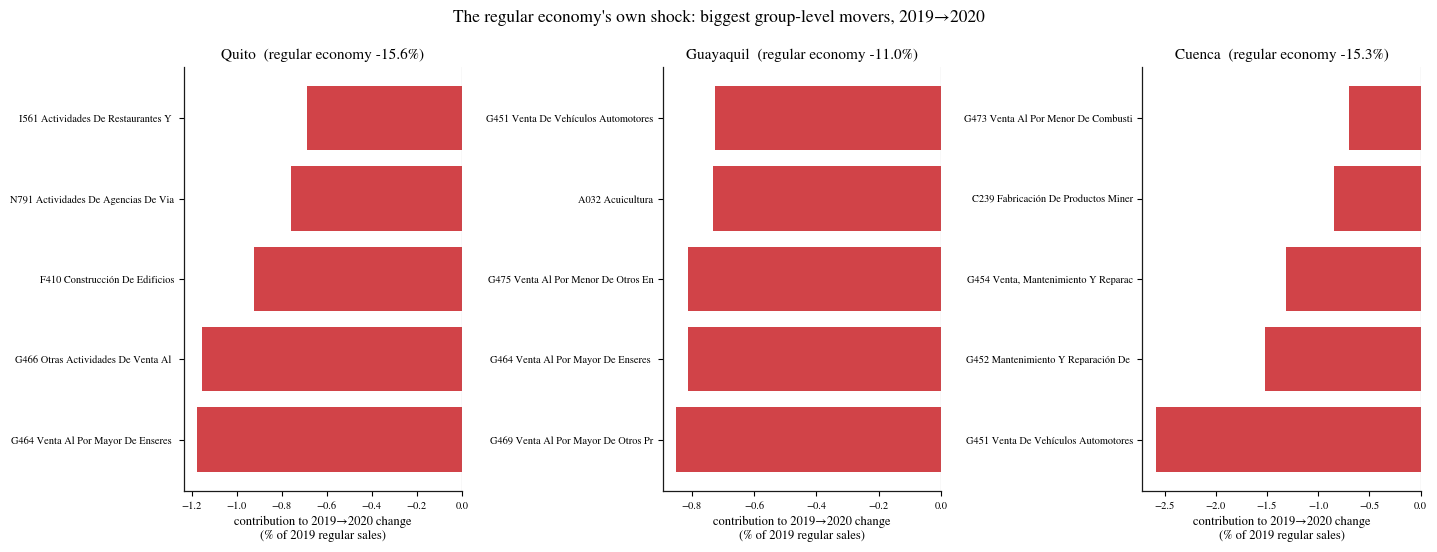

In [14]:
# ==============================================================================
# STEP F -- top group contributions to the 2019->2020 regular-economy change
# ==============================================================================
K = 5
regd = fpr[~fpr["outlier"]]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 5.6))
for ax, (u, lab) in zip(axes, METROS.items()):
    g = (regd[(regd["unit"] == u) & regd["year"].isin([SHOCK_Y0, SHOCK_Y1])]
         .groupby(["grp", "year"], observed=True)["sales"].sum().unstack(fill_value=0.0))
    contrib = (g[SHOCK_Y1] - g[SHOCK_Y0]) / g[SHOCK_Y0].sum() * 100   # % of 2019 regular
    top = contrib.reindex(contrib.abs().nlargest(K).index).sort_values()
    colors = [CUSTOM_RED if v < 0 else style.BLUE for v in top]
    ax.barh([f"{g_} {gname(g_, 30)}" for g_ in top.index], top.values,
            color=colors, alpha=0.85)
    ax.axvline(0, color="0.5", lw=0.8)
    ax.set_title(f"{lab}  (regular economy {contrib.sum():+.1f}%)", fontsize=11)
    ax.set_xlabel(f"contribution to {SHOCK_Y0}→{SHOCK_Y1} change\n(% of 2019 regular sales)",
                  fontsize=9)
    ax.tick_params(labelsize=7.5)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
fig.suptitle("The regular economy's own shock: biggest group-level movers, "
             f"{SHOCK_Y0}→{SHOCK_Y1}", fontsize=12.5)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig4_regular_shock_drivers.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "fig4_regular_shock_drivers.pdf", bbox_inches="tight")
print("saved ->", OUT_DIR / "fig4_regular_shock_drivers.png")
plt.show()

## STEP M — are the "no extreme falls" in broad economies more than luck, or more than size?

FIG 3 leaves one sentence standing: *the catastrophic falls all happened in narrow
economies*. Stated as "the worst fall among the broad parishes is mild, the worst among the
rest is terrible", it has a built-in flaw: the broad group is **small**, and the worst value
of a small group is almost always milder than the worst value of a big one. Pick any 14
parishes out of 174 and you will probably miss the handful of disasters.

So the honest question is: **how unusual is the broad group compared with any group of the
same size?** The cell answers it by brute force (a *permutation test*):

1. Take the broad group (at least `NEFF_HI` effective activities). Write down its worst fall.
2. Draw the same number of parishes **at random** and write down *their* worst fall. Repeat
   20,000 times.
3. Count how often a random group does as well as the broad one. That share is the
   probability of seeing a result this good **by luck alone**. Small = not luck.

Then the same thing with one change, to deal with size. Broad parishes are big parishes
(STEP G), and a big parish's total cannot swing as wildly as a tiny one's. So the second
version draws the random groups **only from the largest parishes**. If broad parishes still
stand out among parishes of their own size, breadth is adding something; if they do not,
the result is about size.

In [15]:
# ==============================================================================
# STEP M -- the tail claim as a permutation test: luck? size?
# ------------------------------------------------------------------------------
# Compares the WORST trough of the broad group with the worst trough of random
# groups of the same size, drawn (a) from all sample parishes, (b) from the
# largest parishes only. Run on the regular economy (the thesis statement) and
# on the full economy.
# ==============================================================================
N_DRAWS   = 20_000     # random groups per test
SIZE_POOL = 3          # size-matched pool = the SIZE_POOL x (group size) largest parishes
SEED      = 0          # fixed, so the printed percentages are reproducible

rng = np.random.default_rng(SEED)
by_size = ANN_FIRMS.loc[KEEP, T0_YEAR].sort_values(ascending=False).index   # largest first

def tail_test(breadth, trough, label):
    """One row: the broad group's worst trough, and how often a random group of the
    same size does at least as well."""
    broad = breadth >= NEFF_HI
    k = int(broad.sum())
    worst_broad = trough[broad].min()
    values = trough.reindex(KEEP).values
    pool_all = np.arange(len(KEEP))
    pool_big = np.array([KEEP.index(u) for u in by_size[:SIZE_POOL * k]])
    def share_as_good(pool):
        worst = np.array([values[rng.choice(pool, k, replace=False)].min()
                          for _ in range(N_DRAWS)])
        return float((worst >= worst_broad).mean())
    return {"economy": label, "broad_parishes": k,
            "worst_trough_broad": worst_broad, "worst_trough_rest": trough[~broad].min(),
            "random_group_as_good": share_as_good(pool_all),
            "random_LARGE_group_as_good": share_as_good(pool_big),
            "size_pool": len(pool_big)}

TAIL = pd.DataFrame([tail_test(DIV["neff_sales_reg"], RES["res_reg"], "regular"),
                     tail_test(DIV["neff_sales"],     RES["res_tot"], "full")]).set_index("economy")
TAIL.to_csv(OUT_DIR / "tail_permutation_test.csv")

for eco, r in TAIL.iterrows():
    print(f"--- {eco} economy: {int(r.broad_parishes)} parishes with >= {NEFF_HI} effective activities ---")
    print(f"  worst trough: broad {r.worst_trough_broad:+.2f}   everyone else {r.worst_trough_rest:+.2f}")
    print(f"  a random group of {int(r.broad_parishes)} parishes does at least as well "
          f"{r.random_group_as_good:.1%} of the time")
    print(f"  a random group of {int(r.broad_parishes)} drawn from the {int(r.size_pool)} largest "
          f"parishes does so {r.random_LARGE_group_as_good:.1%} of the time\n")
print("reading: below 5% is the usual line for 'not luck'. The second percentage is the one\n"
      "that matters for the breadth-or-size question.")

--- regular economy: 13 parishes with >= 30 effective activities ---
  worst trough: broad -0.27   everyone else -2.15
  a random group of 13 parishes does at least as well 1.4% of the time
  a random group of 13 drawn from the 39 largest parishes does so 4.4% of the time

--- full economy: 9 parishes with >= 30 effective activities ---
  worst trough: broad -0.25   everyone else -2.15
  a random group of 9 parishes does at least as well 4.3% of the time
  a random group of 9 drawn from the 27 largest parishes does so 6.3% of the time

reading: below 5% is the usual line for 'not luck'. The second percentage is the one
that matters for the breadth-or-size question.


### What the test says

- **Regular economy.** The 13 broad parishes' worst fall is −0.27; among the other 161 it is
  −2.15. A random group of 13 does that well only **1.4 %** of the time, so it is not luck.
  Drawn only from the 39 largest parishes, a random group does that well **4.4 %** of the
  time: still unusual, but only just under the 5 % line.
- **Full economy.** With 9 broad parishes the two figures are 4.3 % and **6.3 %**, the second
  one above the line.

So the tail result is real as a pattern and **mostly, not entirely, a size result**: once
broad parishes are compared with parishes as big as they are, the evidence is borderline.

### STEP M (cont.) — breadth and size in the same equation

The permutation test compares groups. A regression lets breadth and size compete directly,
parish by parish: *holding the number of firms fixed, does a broader mix still go with a
better outcome?* Three versions of that question, because the claim is about the **bad end**
of the distribution and not about the average:

| version | what it asks | how |
| --- | --- | --- |
| the average | do broader parishes fall less **on average**? | ordinary least squares |
| the bad end | is the **10th-percentile** outcome (a bad year) better for broader parishes? | quantile regression at 0.10 |
| the scatter | are the outcomes of broader parishes **closer together**? | regress the log of each parish's distance from its predicted value on the same two variables; a negative number means less scatter |

Each is run with `ln(firms)` and `ln(breadth)` together, so a coefficient reads "the effect
of this one with the other held fixed". A star marks p < 0.05. **Caution:** breadth and size
are strongly correlated here, which makes it hard for any regression to tell them apart;
treat the signs as evidence and the exact numbers as soft.

In [16]:
# ==============================================================================
# STEP M (cont.) -- breadth vs size: the average, the bad end, the scatter
# ==============================================================================
import statsmodels.api as sm

X = sm.add_constant(pd.DataFrame({"ln_firms":   np.log(ANN_FIRMS.loc[KEEP, T0_YEAR]),
                                  "ln_breadth": np.log(DIV["neff_sales_reg"])}))
OUTCOMES = [("regular-economy trough", RES["res_reg"]),
            ("full-economy trough",    RES["res_tot"]),
            ("firm growth 2019->20",   G_FIRMS)]

def coef(model, name):
    return f"{model.params[name]:+.3f}{'*' if model.pvalues[name] < 0.05 else ' '}"

rows = []
print(f"{'outcome':24s} {'':10s} {'size':>9s} {'breadth':>9s}")
for label, y in OUTCOMES:
    average = sm.OLS(y, X).fit(cov_type="HC1")
    bad_end = sm.QuantReg(y, X).fit(q=0.10)
    scatter = sm.OLS(np.log(average.resid.abs() + 1e-6), X).fit(cov_type="HC1")
    for version, m in [("average", average), ("bad end", bad_end), ("scatter", scatter)]:
        print(f"{label:24s} {version:10s} {coef(m, 'ln_firms'):>9s} {coef(m, 'ln_breadth'):>9s}")
        rows.append({"outcome": label, "version": version,
                     "size_coef": m.params["ln_firms"], "size_p": m.pvalues["ln_firms"],
                     "breadth_coef": m.params["ln_breadth"], "breadth_p": m.pvalues["ln_breadth"]})
    print()
pd.DataFrame(rows).to_csv(OUT_DIR / "breadth_vs_size_regressions.csv", index=False)
r = sps.spearmanr(X["ln_firms"], X["ln_breadth"])
print(f"* p < 0.05.  breadth and size move together (Spearman {r.statistic:+.2f}), "
      "so read signs, not decimals.")

outcome                                  size   breadth
regular-economy trough   average      -0.020    +0.103 
regular-economy trough   bad end      -0.012    +0.181*
regular-economy trough   scatter      -0.045    -0.599*

full-economy trough      average      -0.026    +0.106 
full-economy trough      bad end      -0.032    +0.194*
full-economy trough      scatter      +0.089    -0.749*

firm growth 2019->20     average      +0.006    +0.009 
firm growth 2019->20     bad end      +0.009    +0.014 
firm growth 2019->20     scatter      -0.318*   +0.277 

* p < 0.05.  breadth and size move together (Spearman +0.69), so read signs, not decimals.


### What the regressions say

- **Depth of the sales fall.** On average neither size nor breadth matters. At the **bad end**
  breadth does (+0.18 and +0.19, significant) and size does not: with size held fixed, a
  broader parish's bad-case fall is milder. And broader parishes are **less scattered**
  (−0.60 and −0.75, significant), again with size adding nothing.
- **Growth of the number of firms.** The reverse: it is **size** that goes with less scatter
  (−0.32, significant) and breadth adds nothing.

Put together: for *sales*, what goes with avoiding the worst outcomes is a broad mix; for the
*firm base*, it is being big. That refines the earlier reading "net out size and nothing is
left", which was measured on firm growth only. The caution stands — the two variables are
correlated at +0.69 and this is one specification — and nothing here shows that broadening a
parish's mix would protect it: a total made of many activities is steadier than a total made
of one, by arithmetic.

## STEP N — how much of a parish's fall was just its mix of activities?

In 2020 hotels collapsed and supermarkets did not. A parish that lived on hotels was always
going to fall more than one that lived on supermarkets, whatever else was true of it. This
step separates that **mix effect** from everything else, with a calculation known as
*shift-share*:

1. For each activity, measure how its sales changed between 2019 and 2020 **in the rest of
   the country** (every parish except the one being examined, so a parish never explains
   itself — this matters for Quito and Guayaquil, which are a large part of the national
   total).
2. Apply those national changes to the parish's own 2019 mix. The result is what the parish
   *would have done* if each of its activities had behaved exactly as it did elsewhere.
   That is the **mix-predicted** change.
3. Subtract it from what actually happened. What is left is the **local remainder**:
   everything that is specific to the place and not explained by what it sells.

$$\underbrace{g_p}_{\text{actual}} \;=\; \underbrace{\sum_a s_{pa}\, g_a^{\text{rest}}}_{\text{mix-predicted}} \;+\; \underbrace{\ell_p}_{\text{local remainder}}$$

with $s_{pa}$ the share of activity $a$ in parish $p$'s 2019 sales and $g_a^{\text{rest}}$
the growth of that activity outside $p$. Example: a parish with half its sales in hotels
(−50 % elsewhere) and half in food retail (+4 % elsewhere) has a mix-predicted change of
−23 %; if it actually fell 30 %, its local remainder is −7 points.

Two questions follow. How much of the difference between parishes does the mix explain? And
is breadth related to either part? If diversification protects, broader parishes should
show a milder mix-predicted change (a spread-out mix dilutes the hard-hit activities) or a
better local remainder.

In [17]:
# ==============================================================================
# STEP N -- shift-share: mix-predicted change vs local remainder, 2019 -> 2020
# ------------------------------------------------------------------------------
# Growth is the simple rate (sales_2020 / sales_2019 - 1): with rates, the
# activities' contributions add up exactly to the parish total. "Rest of the
# country" = national sales of the activity minus the parish's own.
# ==============================================================================
def shift_share(y0, y1):
    """One row per sample parish: actual change, mix-predicted change, remainder."""
    own  = ANN_GRP[[y0, y1]].rename(columns={y0: "own0", y1: "own1"})
    nat  = NAT_GRP[[y0, y1]].rename(columns={y0: "nat0", y1: "nat1"})
    t = own.join(nat, on="grp")
    rest0, rest1 = t["nat0"] - t["own0"], t["nat1"] - t["own1"]
    # growth of the activity elsewhere; if the parish is the only one in the
    # activity, fall back on the growth of the whole rest of the country
    rest_all = (nat["nat1"].sum() - t.groupby("unit")["own1"].transform("sum")) \
             / (nat["nat0"].sum() - t.groupby("unit")["own0"].transform("sum")) - 1
    g_rest = (rest1 / rest0.where(rest0 > 0) - 1).fillna(rest_all)
    total0 = t.groupby("unit")["own0"].transform("sum")
    share = t["own0"] / total0
    out = pd.DataFrame({
        "actual": t.groupby("unit")["own1"].sum() / t.groupby("unit")["own0"].sum() - 1,
        "mix_predicted": (share * g_rest).groupby("unit").sum()})
    out["local_remainder"] = out["actual"] - out["mix_predicted"]
    return out.reindex(KEEP)

SS = shift_share(SHOCK_Y0, SHOCK_Y1)
SS["breadth"] = DIV["neff_sales"]
SS.insert(0, "name", [uname(u) for u in KEEP])

# An activity that more than DOUBLED nationally in one year did not "grow": one
# new giant appeared (in 2020, the Fruta del Norte gold mine inside B072). A
# parish that lives on that activity is then "predicted" to double too, which
# says nothing about it. Such parishes are marked and set aside when the size
# of the mix effect is measured; the rank correlation uses every parish.
BOOM = 1.0             # an activity whose national sales grew by more than +100%
national_growth = NAT_GRP[SHOCK_Y1] / NAT_GRP[SHOCK_Y0].where(NAT_GRP[SHOCK_Y0] > 0) - 1
boom_grps = national_growth.index[national_growth > BOOM]
own19 = ANN_GRP[SHOCK_Y0]
boom_share = (own19[own19.index.get_level_values("grp").isin(boom_grps)].groupby("unit").sum()
              / own19.groupby("unit").sum()).reindex(KEEP).fillna(0.0)
SS["boom_activity_share"] = boom_share
SS["set_aside"] = boom_share > 0.5
SS.to_csv(OUT_DIR / "shift_share_2019_2020.csv")
REST = SS[~SS["set_aside"]]

nat_change = NAT_GRP[SHOCK_Y1].sum() / NAT_GRP[SHOCK_Y0].sum() - 1
r_mix = sps.spearmanr(SS["actual"], SS["mix_predicted"])
r2 = np.corrcoef(REST["actual"], REST["mix_predicted"])[0, 1] ** 2
r2_all = np.corrcoef(SS["actual"], SS["mix_predicted"])[0, 1] ** 2
print(f"national change {SHOCK_Y0}->{SHOCK_Y1}, private companies: {nat_change:+.1%};  "
      f"median sample parish: {SS['actual'].median():+.1%}")
print(f"\nset aside ({int(SS['set_aside'].sum())} parishes with more than half their sales in an "
      f"activity that more than doubled nationally):")
for u, r in SS[SS["set_aside"]].iterrows():
    print(f"   {r['name']:45s} actual {r['actual']:+.1%}   mix-predicted {r['mix_predicted']:+.1%}")
print(f"\nhow much is mix?  actual vs mix-predicted, all {len(SS)} parishes: Spearman "
      f"{r_mix.statistic:+.2f} (p = {r_mix.pvalue:.4f})")
print(f"  the mix explains {r2:.0%} of the differences between the other {len(REST)} parishes "
      f"({r2_all:.0%} if the set-aside ones are kept in)")
print(f"  spread across those parishes (standard deviation): actual {REST['actual'].std():.3f}, "
      f"mix-predicted {REST['mix_predicted'].std():.3f}, local remainder {REST['local_remainder'].std():.3f}")

print("\nis breadth related to either part? (Spearman)")
for col, txt in [("actual", "actual change   "), ("mix_predicted", "mix-predicted   "),
                 ("local_remainder", "local remainder ")]:
    r = sps.spearmanr(SS["breadth"], SS[col])
    print(f"  {txt}: rho = {r.statistic:+.3f}  (p = {r.pvalue:.4f})")

print("\nthe metros:")
for u, lab in METROS.items():
    print(f"  {lab:10s} actual {SS.loc[u, 'actual']:+.1%}   mix-predicted "
          f"{SS.loc[u, 'mix_predicted']:+.1%}   local remainder {SS.loc[u, 'local_remainder']:+.1%}")

national change 2019->2020, private companies: -12.6%;  median sample parish: -10.2%

set aside (2 parishes with more than half their sales in an activity that more than doubled nationally):
   Portovelo (Portovelo)                         actual +18.5%   mix-predicted +117.5%
   San Carlos De Las Minas (Zamora)              actual -3.5%   mix-predicted +205.2%

how much is mix?  actual vs mix-predicted, all 174 parishes: Spearman +0.53 (p = 0.0000)
  the mix explains 12% of the differences between the other 172 parishes (7% if the set-aside ones are kept in)
  spread across those parishes (standard deviation): actual 0.202, mix-predicted 0.141, local remainder 0.203

is breadth related to either part? (Spearman)
  actual change   : rho = -0.105  (p = 0.1664)
  mix-predicted   : rho = -0.077  (p = 0.3108)
  local remainder : rho = -0.066  (p = 0.3888)

the metros:
  Quito      actual -20.3%   mix-predicted -14.7%   local remainder -5.6%
  Guayaquil  actual -10.6%   mix-predicted -10.9%

### What the split says

- **The mix matters for the ranking.** Parishes ordered by what their mix predicted are, to a
  good extent, ordered the same way by what happened (rank correlation **+0.53**). What a
  place sells tells you a lot about how hard 2020 hit it.
- **How *much* of the differences it explains is not a number to quote.** In growth rates the
  answer swings between 7 % and about 30 % depending on a handful of mining parishes and on
  whether "the rest of the country" means all parishes or the sample. One activity alone does
  this: gold mining (B072) tripled nationally in 2020 because one new mine opened, so every
  small gold parish is "predicted" to triple. Use the rank correlation.
- **Breadth is unrelated to either part** (all three correlations small and not
  significant). Broader parishes did not have a milder mix-predicted fall, and they did not do
  better than their mix predicted. On average, diversification did not help — the same answer
  as FIG 3, now with the reason split in two.
- **Quito** fell 20.3 %, of which its mix predicted 14.7 %: it did 5.6 points *worse* than
  its activities did elsewhere. Guayaquil and Cuenca landed almost exactly where their mix
  predicted.

## STEP O — does the same pattern appear in a different downturn? 2015 → 2016

Everything above rests on one event. A result seen once could be a peculiarity of the
pandemic. The sales extract starts in 2015, and 2015 → 2016 was a downturn of its own: oil
prices had collapsed and the April 2016 earthquake hit the coast. It is a different shock,
with different activities and places affected, **in the same data** — a free second test.

The cell repeats the FIG 3 comparison with nothing changed but the years: breadth is
measured on each parish's 2015 sales shares, the outcome is the change in annual real sales
from 2015 to 2016, the parishes are the same 174. The registry of companies only starts in
2017, so this check exists for sales and not for the number of firms.

If breadth again fails to predict the average change **and** the extreme falls again sit in
the narrow economies, the pattern is not a one-off.

In [18]:
# ==============================================================================
# STEP O -- the 2015 -> 2016 downturn: same parishes, same construction
# ==============================================================================
EARLY_Y0, EARLY_Y1 = 2015, 2016

sales0 = ANN_GRP[EARLY_Y0].groupby("unit").sum().reindex(KEEP)
sales1 = ANN_GRP[EARLY_Y1].groupby("unit").sum().reindex(KEEP)
alive = (sales0 > 0) & (sales1 > 0)
change_early = np.log(sales1[alive] / sales0[alive])

W_early = ANN_GRP[EARLY_Y0].unstack("grp", fill_value=0.0).reindex(change_early.index).fillna(0.0)
breadth_early = variety(W_early, "early")["neff_early"]

EARLY = pd.DataFrame({"name": [uname(u) for u in change_early.index],
                      "breadth_2015": breadth_early, "change_2015_2016": change_early})
EARLY.to_csv(OUT_DIR / "early_downturn_2015_2016.csv")

nat_early = np.log(NAT_GRP[EARLY_Y1].sum() / NAT_GRP[EARLY_Y0].sum())
r = sps.spearmanr(breadth_early, change_early)
broad = breadth_early >= NEFF_HI
print(f"national change {EARLY_Y0}->{EARLY_Y1}, private companies: {nat_early:+.3f} log pts;  "
      f"{len(change_early)} parishes; {(change_early < 0).mean():.0%} of them fell")
print(f"\nbreadth vs change: Spearman rho = {r.statistic:+.3f}  (p = {r.pvalue:.4f})")
print(f"worst change among the {int(broad.sum())} parishes with >= {NEFF_HI} effective "
      f"activities: {change_early[broad].min():+.2f} log pts")
print(f"worst among the other {int((~broad).sum())}:                                  "
      f"{change_early[~broad].min():+.2f} log pts")

# the same luck / size check as STEP M
k = int(broad.sum()); vals = change_early.values
big = np.argsort(-ANN_FIRMS.loc[change_early.index, T0_YEAR].values)[:SIZE_POOL * k]
worst_any = np.array([vals[rng.choice(len(vals), k, replace=False)].min() for _ in range(N_DRAWS)])
worst_big = np.array([vals[rng.choice(big, k, replace=False)].min() for _ in range(N_DRAWS)])
print(f"a random group of {k} does at least as well {np.mean(worst_any >= change_early[broad].min()):.1%} "
      f"of the time; drawn from the {len(big)} largest parishes, "
      f"{np.mean(worst_big >= change_early[broad].min()):.1%}")
print("\nthe metros:  " + "   ".join(f"{lab} {change_early[u]:+.3f} (breadth {breadth_early[u]:.0f})"
                                    for u, lab in METROS.items()))

national change 2015->2016, private companies: -0.088 log pts;  174 parishes; 63% of them fell

breadth vs change: Spearman rho = -0.109  (p = 0.1508)
worst change among the 7 parishes with >= 30 effective activities: -0.14 log pts
worst among the other 167:                                  -0.86 log pts
a random group of 7 does at least as well 12.7% of the time; drawn from the 21 largest parishes, 27.3%

the metros:  Quito -0.122 (breadth 60)   Guayaquil -0.081 (breadth 61)   Cuenca -0.135 (breadth 43)


### What the second downturn says

Same direction, weaker evidence. Breadth again does not predict the average change (−0.11,
not significant), and again the worst case among broad parishes (−0.14) is far milder than
among the rest (−0.86). But only 7 parishes were broad in 2015, and a random group of 7 does
as well **12.7 %** of the time (27.3 % among the largest parishes). So 2015–2016 does not
contradict the pandemic result, and it does not confirm it either: on its own it could be
luck. It is reported as a check that came back inconclusive, not as support.